# Challenge 1: Transaction fraud

## The problem in plain words
The fraud team wants to **spot suspicious transactions without creating too many unnecessary investigations**. I have to build a small, practical method to **flag or prioritise** transactions, show why it is useful, explain the **trade-off between catching fraud and inconveniencing legitimate customers**, and explain how a fraud operations team could act on the result.

## The trade-off, simply
Every transaction the team reviews is a choice. **Review more**, and more fraud is caught, but more genuine customers are contacted or delayed. **Review fewer**, and customers are left alone, but more fraud slips through. No method removes this trade-off. This notebook ranks transactions by risk so the team can **review the riskiest first**, shows in plain numbers what each review volume gains and costs, and leaves the choice of volume to the bank.

### Assumption: what does "fraud" mean here?
The data dictionary only defines `is_fraud` as the *historical fraud-confirmation outcome* (1 = confirmed fraud). It does not say who committed the fraud or how, so I make the following **assumption**:

> **`is_fraud = 1` means a confirmed *unauthorized* transaction made by a third party on the customer's account** (e.g. account takeover or stolen credentials/card details), **not** fraud committed by the customer themselves.

**Evidence from the features:**
| Feature | Why it points to third-party / account-takeover fraud |
|---|---|
| `new_device_flag` | Strongest signal in the data (13.3% fraud vs 3.2%). Fits a login from a device the customer never used. |
| `failed_login_attempts_prev_24h` | Fits password guessing / credential stuffing before a successful login. |
| `new_beneficiary_flag` | Fits money being sent to an account the fraudster controls (a new payee for the victim). |
| Amount far above the customer's 30-day norm; bursts of transactions in 24h | Fits a fraudster draining an account quickly. |
| `international_card_flag`, e-commerce | Fits stolen card details used online. |

First-party fraud (the customer disputing or lying about their own purchase) would normally need fields such as disputes or chargebacks, and would not come with new devices, and none exist in this data.

**Limitation:** a *scam* where the customer is tricked into sending the money themselves also shows a new beneficiary and a large amount, usually on a known device. Nothing here separates that from account takeover, so "confirmed fraud" may include both.

**Why it matters for action:** for account takeover, the fraud team would **block the session/transaction and contact the customer**; for scams, a **warning message before the transfer** is more appropriate. I would confirm the definition with the fraud team before deployment.

### Setup guide
**Setup:** Python 3.15+ with the packages in `pyproject.toml` (`uv sync`), then run all cells. The cross-validation cells in sections 7 and 9 take the longest (a few minutes).

| Part | What it covers | |
|---|---|---|
| 1. Cleaning, 2. EDA, 3. Outliers | Is the data sound, and which signals separate fraud from legitimate transactions | **Core** |
| 4. Random forest, 5. Logistic regression | A simple risk rule and two models, compared on a held-out month | **Core** |
| 8. What drives the score | What the recommended model relies on, and three worked examples (caught, false alarm, missed) | **Core** |
| 10. The trade-off and the action plan | What each review volume gains and costs, and what the fraud team does at each risk level | **Core** |
| 11. Control panel | How the bank adjusts the alert volume itself | **Core** |
| 6. Gradient boosting, 7. Grouped cross-validation, 9. Calibration | Extra evidence for technical reviewers: another model, a firmer comparison on all 245 frauds, and checking that scores behave like real probabilities | *Supplementary* |

**TLDR Recommendation** rank transactions with the regularised logistic regression, send the top few percent to the fraud team with the warning signs attached, and let the bank choose the review volume that balances fraud caught against customers contacted.

In [55]:
import pandas as pd
import numpy as np


In [56]:
# Path to the dataset. Change this line if your CSV is somewhere else (see README).
FRAUD_CSV = "Interview Case Study/digital_bank_fraud_transactions.csv"
fraud_df = pd.read_csv(FRAUD_CSV)
fraud_df.head()

,transaction_id,customer_id,transaction_datetime,transaction_type,channel,transaction_amount_pkr,avg_txn_amount_prev_30d_pkr,txn_count_prev_24h,account_age_days,new_device_flag,new_beneficiary_flag,failed_login_attempts_prev_24h,international_card_flag,is_fraud
0,TX800001,F200456,2026-07-01 00:09:43,Card Purchase,POS,78043,11543,10,1105,0,0,0,0,1
1,TX800002,F200672,2026-07-01 00:20:00,Raast Transfer,Mobile App,439,1033,0,1529,0,0,0,0,0
2,TX800003,F200448,2026-07-01 00:20:22,IBFT Transfer,Mobile App,10761,6312,1,381,0,0,0,0,0
3,TX800004,F200884,2026-07-01 00:41:00,Raast Transfer,Mobile App,22901,7370,0,788,0,0,0,0,0
4,TX800005,F200311,2026-07-01 00:58:44,Bill Payment,Mobile App,87231,20556,0,397,0,0,0,0,0


In [57]:
fraud_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   transaction_id                  6000 non-null   str  
 1   customer_id                     6000 non-null   str  
 2   transaction_datetime            6000 non-null   str  
 3   transaction_type                6000 non-null   str  
 4   channel                         6000 non-null   str  
 5   transaction_amount_pkr          6000 non-null   int64
 6   avg_txn_amount_prev_30d_pkr     6000 non-null   int64
 7   txn_count_prev_24h              6000 non-null   int64
 8   account_age_days                6000 non-null   int64
 9   new_device_flag                 6000 non-null   int64
 10  new_beneficiary_flag            6000 non-null   int64
 11  failed_login_attempts_prev_24h  6000 non-null   int64
 12  international_card_flag         6000 non-null   int64
 13  is_fraud      

In [58]:
fraud_df.describe()

,transaction_amount_pkr,avg_txn_amount_prev_30d_pkr,txn_count_prev_24h,account_age_days,new_device_flag,new_beneficiary_flag,failed_login_attempts_prev_24h,international_card_flag,is_fraud
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,11438.053167,6808.441167,2.182833,934.290167,0.091500,0.088167,0.195667,0.008000,0.040833
std,24469.047879,6005.115608,2.341934,491.360944,0.288343,0.283561,0.625923,0.089092,0.197920
min,100.000000,312.000000,0.000000,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2271.500000,3004.000000,1.000000,509.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4936.500000,5002.000000,2.000000,946.500000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,11232.500000,8410.250000,3.000000,1366.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,350000.000000,55713.000000,16.000000,1787.000000,1.000000,1.000000,4.000000,1.000000,1.000000


## 1. Data cleaning & validation
Checks: duplicates, nulls, data types, categorical values, valid ranges, consistency between related fields.

In [59]:
# Convert datetime from string; everything else already has the right data type
fraud_df["transaction_datetime"] = pd.to_datetime(fraud_df["transaction_datetime"], errors="coerce")
print("Unparseable datetimes:", fraud_df["transaction_datetime"].isna().sum())
print("Date range:", fraud_df["transaction_datetime"].min(), "->", fraud_df["transaction_datetime"].max())
print("Sorted by time:", fraud_df["transaction_datetime"].is_monotonic_increasing)

Unparseable datetimes: 0
Date range: 2026-07-01 00:09:43 -> 2026-09-30 23:56:13
Sorted by time: True


In [60]:
# Nulls and duplicates
print("Nulls:", fraud_df.isna().sum().sum())
print("Duplicate rows:", fraud_df.duplicated().sum())
print("Duplicate transaction_id:", fraud_df["transaction_id"].duplicated().sum())

# ID formats (TX-prefixed / F-prefixed, no stray whitespace)
print("transaction_id format ok:", fraud_df["transaction_id"].str.fullmatch(r"TX\d+").all())
print("customer_id format ok:", fraud_df["customer_id"].str.fullmatch(r"F\d+").all())

Nulls: 0
Duplicate rows: 0
Duplicate transaction_id: 0
transaction_id format ok: True
customer_id format ok: True


In [61]:
# Categorical values vs data dictionary
valid_types = {"Raast Transfer","IBFT Transfer","Card Purchase","Bill Payment","ATM Withdrawal"}
valid_channels = {"Mobile App","POS","E-commerce","ATM"}
print("Unexpected types:", set(fraud_df["transaction_type"]) - valid_types)
print("Unexpected channels:", set(fraud_df["channel"]) - valid_channels)

# Binary columns contain only 0/1
for c in ["new_device_flag","new_beneficiary_flag","international_card_flag","is_fraud"]:
    print(c, sorted(fraud_df[c].unique()))

Unexpected types: set()
Unexpected channels: set()
new_device_flag [np.int64(0), np.int64(1)]
new_beneficiary_flag [np.int64(0), np.int64(1)]
international_card_flag [np.int64(0), np.int64(1)]
is_fraud [np.int64(0), np.int64(1)]


In [62]:
# Logical consistency between fields
print(pd.crosstab(fraud_df["transaction_type"], fraud_df["channel"]), "\n")
print("new_beneficiary on non-transfer types:",
      ((fraud_df["new_beneficiary_flag"] == 1) & ~fraud_df["transaction_type"].isin(["Raast Transfer","IBFT Transfer"])).sum())
print("international_card on non-card-purchase:",
      ((fraud_df["international_card_flag"] == 1) & (fraud_df["transaction_type"] != "Card Purchase")).sum())
print("Non-positive amounts:", (fraud_df["transaction_amount_pkr"] <= 0).sum())
print("Non-positive 30d averages:", (fraud_df["avg_txn_amount_prev_30d_pkr"] <= 0).sum())
print("Negative counts:", (fraud_df[["txn_count_prev_24h","failed_login_attempts_prev_24h","account_age_days"]] < 0).sum().to_dict())

channel           ATM  E-commerce  Mobile App   POS
transaction_type                                   
ATM Withdrawal    543           0           0     0
Bill Payment        0           0         936     0
Card Purchase       0         681           0  1100
IBFT Transfer       0           0        1182     0
Raast Transfer      0           0        1558     0 

new_beneficiary on non-transfer types: 0
international_card on non-card-purchase: 0
Non-positive amounts: 0
Non-positive 30d averages: 0
Negative counts: {'txn_count_prev_24h': 0, 'failed_login_attempts_prev_24h': 0, 'account_age_days': 0}


In [63]:
# Outliers: amount ceiling and amount relative to the customer's usual spend
print(fraud_df["transaction_amount_pkr"].describe(percentiles=[.5,.9,.99,.999]))
print("\nRows at max amount:", (fraud_df["transaction_amount_pkr"] == fraud_df["transaction_amount_pkr"].max()).sum())
print(fraud_df.loc[fraud_df["transaction_amount_pkr"] == 350000, ["transaction_type","channel","is_fraud"]].value_counts())

ratio = fraud_df["transaction_amount_pkr"] / fraud_df["avg_txn_amount_prev_30d_pkr"]
print("\nAmount / 30d avg ratio:\n", ratio.describe(percentiles=[.5,.9,.99]))

count      6000.000000
mean      11438.053167
std       24469.047879
min         100.000000
50%        4936.500000
90%       24222.400000
99%      105496.090000
99.9%    350000.000000
max      350000.000000
Name: transaction_amount_pkr, dtype: float64

Rows at max amount: 9
transaction_type  channel     is_fraud
Raast Transfer    Mobile App  0           3
Card Purchase     POS         0           2
                  E-commerce  0           2
Bill Payment      Mobile App  0           1
IBFT Transfer     Mobile App  0           1
Name: count, dtype: int64

Amount / 30d avg ratio:
 count    6000.000000
mean        1.662101
std         2.532451
min         0.048852
50%         0.984423
90%         3.342218
99%        13.487024
max        43.608273
dtype: float64


In [64]:
# Customer-level view: how much history per customer is in this sample?
per_cust = fraud_df.groupby("customer_id").size()
print("Customers:", per_cust.shape[0], "| txns per customer:", per_cust.min(), "-", per_cust.max(), "(median", per_cust.median(), ")")
print("Class balance:\n", fraud_df["is_fraud"].value_counts(), "\n", fraud_df["is_fraud"].mean().round(4))

Customers: 949 | txns per customer: 1 - 15 (median 6.0 )
Class balance:
 is_fraud
0    5755
1     245
Name: count, dtype: int64 
 0.0408


### Cleaning findings
- **No nulls, no duplicates**, IDs well-formed, all categories and binary flags match the data dictionary.
- **Only dtype fix needed:** `transaction_datetime` was a string, now parsed to datetime (Jul 1 - Sep 30 2026).
- **Field consistency holds:** transaction type maps cleanly to channel; new-beneficiary only occurs on transfers; international flag only on card purchases (all e-commerce).
- **Amount cap:** 9 transactions sit at exactly PKR 350,000, which looks like a cap/ceiling (true amounts may be higher). All 9 are legitimate, so large amount alone is not a fraud signal. Kept, not removed.
- **Heavy right skew** in amounts and in amount-vs-30d-average ratio (up to ~44x). These are real behaviour, not errors; consider log or ratio features.
- **Class imbalance:** ~4.1% fraud (245 / 6,000), so accuracy is meaningless; use precision/recall and alert-volume.
- **Sample caveat:** ~949 customers with ~6 txns each, so prior-activity fields (`txn_count_prev_24h`, 30d average) reflect activity outside this sample and can't be recomputed from it.

## 2. Exploratory data analysis
Because fraud is rare (~4%), the key question for every feature is:
*does it lift the fraud rate far enough above the 4.1% base rate to be worth acting on?*

Business questions we will answer:
1. **Where** does fraud happen (transaction type / channel)?
2. **What behaviour** looks risky (new device, new beneficiary, failed logins, international card)?
3. Is fraud about **unusually large** amounts, relative to the customer's normal spend?
4. Does **velocity** (many transactions in 24h) matter?
5. Does **time** (hour, weekday) or **account age** matter?
6. Is the pattern **stable over time**, and do **customers repeat**?
7. How far can **simple stacked rules** take us in precision vs. recall?

In [65]:
import matplotlib.pyplot as plt

# Palette: blue = general, orange = fraud / highlight, neutral ink for text
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})

# Derived features used throughout the EDA
eda = fraud_df.copy()
eda["amt_ratio"] = eda["transaction_amount_pkr"] / eda["avg_txn_amount_prev_30d_pkr"]
eda["hour"] = eda["transaction_datetime"].dt.hour
eda["weekday"] = eda["transaction_datetime"].dt.day_name().str[:3]
eda["week"] = eda["transaction_datetime"].dt.to_period("W").dt.start_time
eda["ratio_band"] = pd.cut(eda["amt_ratio"], [0, .5, 1, 2, 3, 5, 10, np.inf],
                           labels=["<0.5x", "0.5-1x", "1-2x", "2-3x", "3-5x", "5-10x", "10x+"])
eda["hour_block"] = pd.cut(eda["hour"], [-1, 5, 11, 17, 23], labels=["00-05", "06-11", "12-17", "18-23"])
eda["age_band"] = pd.cut(eda["account_age_days"], [0, 90, 180, 365, 730, 1095, np.inf],
                         labels=["<3m", "3-6m", "6-12m", "1-2y", "2-3y", "3y+"])
eda["velocity_band"] = pd.cut(eda["txn_count_prev_24h"], [-1, 2, 5, np.inf], labels=["0-2", "3-5", "6+"])
eda["login_band"] = pd.cut(eda["failed_login_attempts_prev_24h"], [-1, 0, 1, np.inf], labels=["0", "1", "2+"])

BASE = eda["is_fraud"].mean()


def rate_table(col):
    g = eda.groupby(col, observed=True)["is_fraud"].agg(n="size", frauds="sum", rate="mean")
    g["lift_vs_base"] = g["rate"] / BASE
    g["share_of_fraud"] = g["frauds"] / g["frauds"].sum()
    return g


def pct_axis(ax, axis="y"):
    fmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


XLABELS = {
    "transaction_type": "Transaction type", "channel": "Channel used",
    "new_device_flag": "Was a new device used?", "new_beneficiary_flag": "Was the recipient new to the customer?",
    "login_band": "Failed login attempts in the previous 24 hours", "international_card_flag": "International card payment?",
    "ratio_band": "Amount compared with customer's usual (times)",
    "velocity_band": "Transactions in the previous 24 hours", "hour_block": "Time of day (hours)",
    "weekday": "Day of the week", "age_band": "Account age", "n_flags": "Number of risk flags that fire",
}
YLABEL_RATE = "Fraud rate (% of transactions)"


def rate_bar(ax, col, title, order=None, labels=None, xlabel=None):
    g = rate_table(col)
    if order is not None:
        g = g.loc[order]
    x = np.arange(len(g))
    ax.bar(x, g["rate"], color=BLUE, width=0.6)
    ax.axhline(BASE, color=INK2, ls="--", lw=1)
    ax.text(len(g) - 0.5, BASE, f" base {BASE:.1%}", va="bottom", ha="right", color=INK2, fontsize=8)
    for xi, (r, n) in enumerate(zip(g["rate"], g["n"])):
        ax.text(xi, r, f"{r:.1%}\nn={n:,}", ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels(labels if labels is not None else [str(i) for i in g.index])
    ax.set_ylim(0, g["rate"].max() * 1.3)
    pct_axis(ax)
    ax.set_title(title)
    ax.set_xlabel(xlabel or XLABELS.get(col, str(col).replace("_", " ").capitalize()))
    ax.set_ylabel(YLABEL_RATE)
    return g

# Plain-language names for the model features, used on the importance / driver charts
FEATURE_NAMES = {
    "log_amount": "Amount (PKR)", "log_avg_30d": "Customer's usual amount", "log_amt_ratio": "Amount compared with usual",
    "txn_count_prev_24h": "Transactions in last 24h", "failed_logins_24h": "Failed logins (24h)", "account_age_days": "Account age",
    "new_device": "New device", "new_beneficiary": "New recipient", "intl_card": "International card", "hour": "Hour of day",
    "is_night": "Night-time (00-05)", "is_weekend": "Weekend", "burst_6plus": "6+ transactions in 24h",
    "hour_sin": "Time of day (part 1)", "hour_cos": "Time of day (part 2)",
}

def nice_names(names):
    out = []
    for n in names:
        if n in FEATURE_NAMES: out.append(FEATURE_NAMES[n])
        elif n.startswith("type_"): out.append("Type: " + n[5:])
        elif n.startswith("chan_"): out.append("Channel: " + n[5:])
        else: out.append(n.replace("_", " "))
    return out


### Q1. Where does fraud happen? (type & channel)

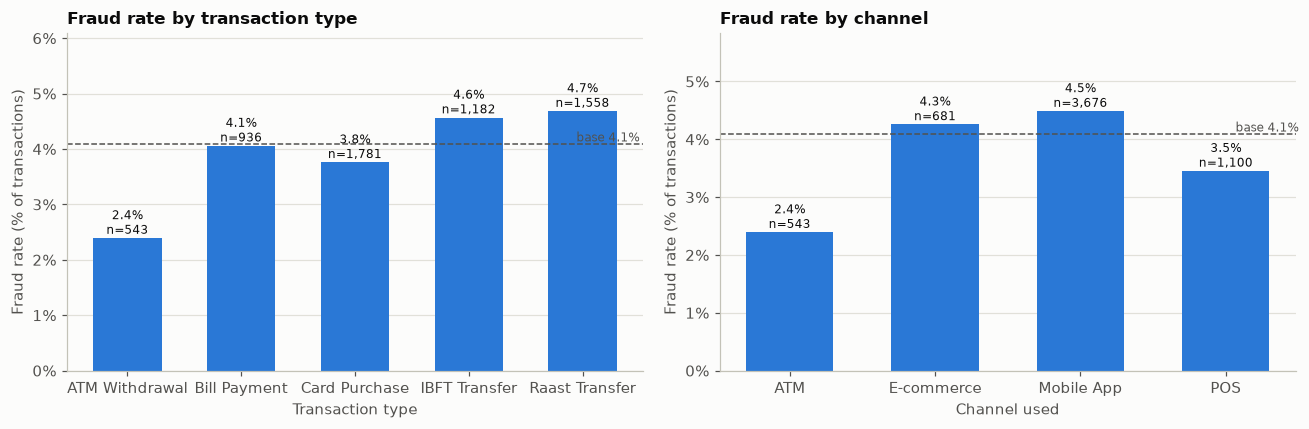

,n,frauds,rate,lift_vs_base,share_of_fraud
transaction_type,,,,,
ATM Withdrawal,543,13,0.024,0.586,0.053
Bill Payment,936,38,0.041,0.994,0.155
Card Purchase,1781,67,0.038,0.921,0.273
IBFT Transfer,1182,54,0.046,1.119,0.220
Raast Transfer,1558,73,0.047,1.147,0.298


In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rate_bar(axes[0], "transaction_type", "Fraud rate by transaction type")
rate_bar(axes[1], "channel", "Fraud rate by channel")
plt.tight_layout(); plt.show()
display(rate_table("transaction_type").round(3))

**Reading:** Transfers (Raast 4.7%, IBFT 4.6%) and the Mobile App channel (4.5%) sit slightly above the 4.1% base rate; ATM withdrawals are lowest (2.4%). The differences are small (roughly 0.6x to 1.15x of base), so **type and channel alone are not good filters**. Mobile App / transfer traffic contributes the most fraud cases simply because it is the largest segment.

### Q2. Which behaviours look risky? (device, beneficiary, logins, international card)

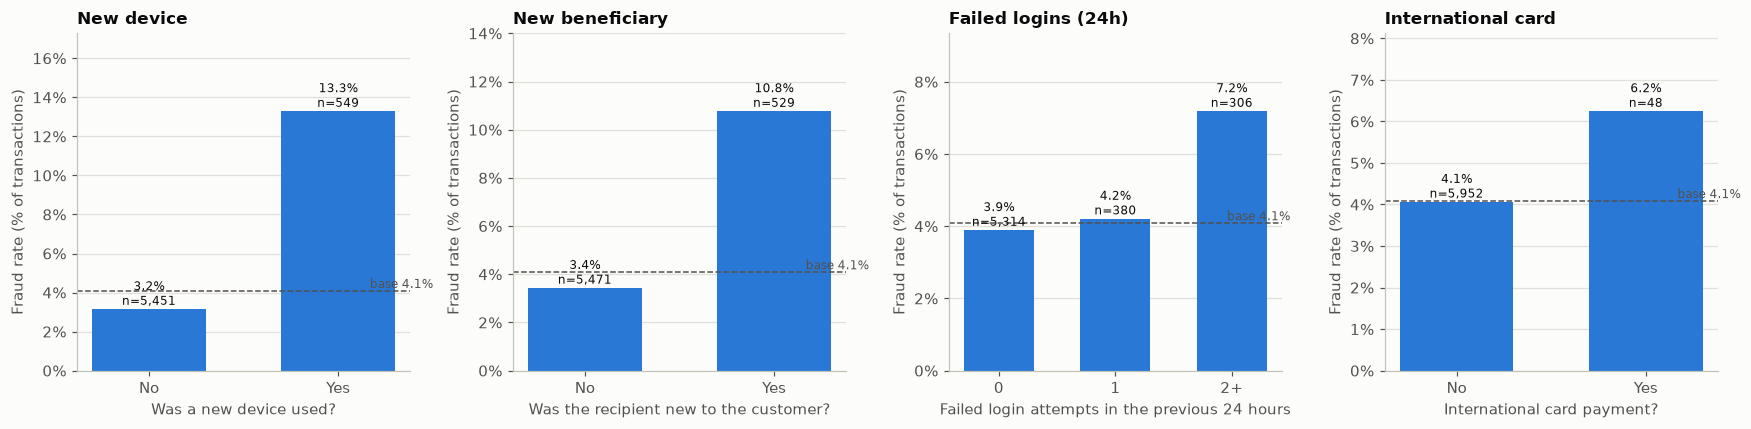

,n,frauds,rate,lift_vs_base,share_of_fraud
new_device_flag,,,,,
0,5451,172,0.032,0.773,0.702
1,549,73,0.133,3.256,0.298


,n,frauds,rate,lift_vs_base,share_of_fraud
new_beneficiary_flag,,,,,
0,5471,188,0.034,0.842,0.767
1,529,57,0.108,2.639,0.233


,n,frauds,rate,lift_vs_base,share_of_fraud
login_band,,,,,
0,5314,207,0.039,0.954,0.845
1,380,16,0.042,1.031,0.065
2+,306,22,0.072,1.761,0.090


,n,frauds,rate,lift_vs_base,share_of_fraud
international_card_flag,,,,,
0,5952,242,0.041,0.996,0.988
1,48,3,0.062,1.531,0.012


In [67]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
rate_bar(axes[0], "new_device_flag", "New device", labels=["No", "Yes"])
rate_bar(axes[1], "new_beneficiary_flag", "New beneficiary", labels=["No", "Yes"])
rate_bar(axes[2], "login_band", "Failed logins (24h)")
rate_bar(axes[3], "international_card_flag", "International card", labels=["No", "Yes"])
plt.tight_layout(); plt.show()
for c in ["new_device_flag", "new_beneficiary_flag", "login_band", "international_card_flag"]:
    display(rate_table(c).round(3))

**Reading:**
- **New device is the strongest single flag:** 13.3% fraud vs 3.2% without (about 3.3x base). It covers ~30% of all fraud but only 9% of transactions.
- **New beneficiary:** 10.8% vs 3.4% (about 2.6x), covering ~23% of fraud.
- **Failed logins:** a mild gradient (3.9% at 0, about 7% at 2+), weaker than the two flags above.
- **International card:** 6.2% but only **48 transactions / 3 frauds**, too few to trust.

Even the best single flag is right only about 1 time in 8 (~13%), which means roughly 6-7 legitimate transactions would be flagged for every real fraud found.

### Q3. Is fraud about unusually large amounts? (amount vs the customer's own norm)

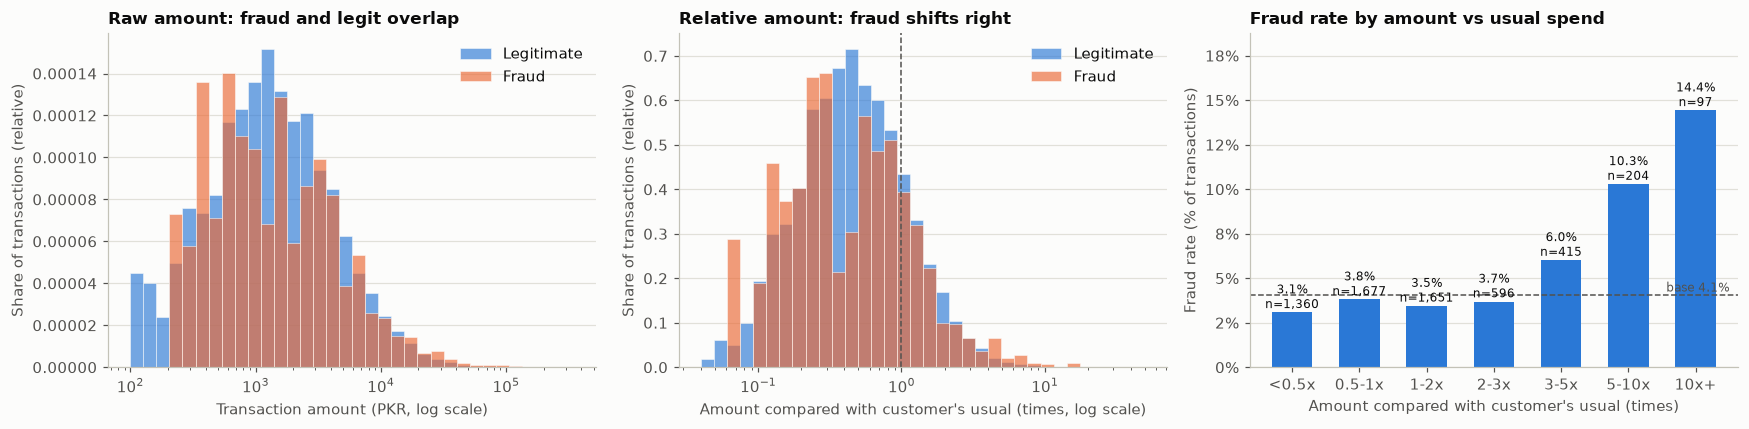

,n,frauds,rate,lift_vs_base,share_of_fraud
ratio_band,,,,,
<0.5x,1360,42,0.031,0.756,0.171
0.5-1x,1677,64,0.038,0.935,0.261
1-2x,1651,57,0.035,0.845,0.233
2-3x,596,22,0.037,0.904,0.090
3-5x,415,25,0.060,1.475,0.102
5-10x,204,21,0.103,2.521,0.086
10x+,97,14,0.144,3.535,0.057


,transaction_amount_pkr,amt_ratio
is_fraud,,
0,4880.0,0.98
1,6903.0,1.20


In [68]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (a) raw amount distribution, log scale - fraud vs legit
bins = np.logspace(2, np.log10(350000), 35)
for flag, color, name in [(0, BLUE, "Legitimate"), (1, ORANGE, "Fraud")]:
    axes[0].hist(eda.loc[eda["is_fraud"] == flag, "transaction_amount_pkr"], bins=bins, density=True,
                 alpha=0.65, color=color, label=name, edgecolor=SURF, linewidth=0.5)
axes[0].set_xscale("log"); axes[0].set_xlabel("Transaction amount (PKR, log scale)"); axes[0].set_ylabel("Share of transactions (relative)")
axes[0].set_title("Raw amount: fraud and legit overlap"); axes[0].legend(frameon=False)

# (b) amount relative to the customer's 30d average
bins = np.logspace(np.log10(0.04), np.log10(50), 35)
for flag, color, name in [(0, BLUE, "Legitimate"), (1, ORANGE, "Fraud")]:
    axes[1].hist(eda.loc[eda["is_fraud"] == flag, "amt_ratio"], bins=bins, density=True,
                 alpha=0.65, color=color, label=name, edgecolor=SURF, linewidth=0.5)
axes[1].set_xscale("log"); axes[1].axvline(1, color=INK2, ls="--", lw=1)
axes[1].set_xlabel("Amount compared with customer's usual (times, log scale)"); axes[1].set_ylabel("Share of transactions (relative)"); axes[1].set_title("Relative amount: fraud shifts right")
axes[1].legend(frameon=False)

# (c) fraud rate by ratio band
rate_bar(axes[2], "ratio_band", "Fraud rate by amount vs usual spend")
plt.tight_layout(); plt.show()
display(rate_table("ratio_band").round(3))
display(eda.groupby("is_fraud")[["transaction_amount_pkr", "amt_ratio"]].median().round(2))

**Reading:** Raw amount barely separates fraud from legit (median PKR 6.9k vs 4.9k, heavy overlap), and the 9 capped PKR 350k transactions were all legitimate. **Relative to the customer's own norm it is much better:** fraud is about 3-4% when spend is under 3x usual, rising to **10% at 5-10x and 14% at 10x+**. This argues for a *personalised* feature (amount / 30d average) over a global amount threshold, which would flag many legitimate high-value customers. Caveat: only ~300 transactions (5%) are 5x+, so on its own it catches few frauds.

### Q4. Does velocity matter? (transactions in the previous 24h)

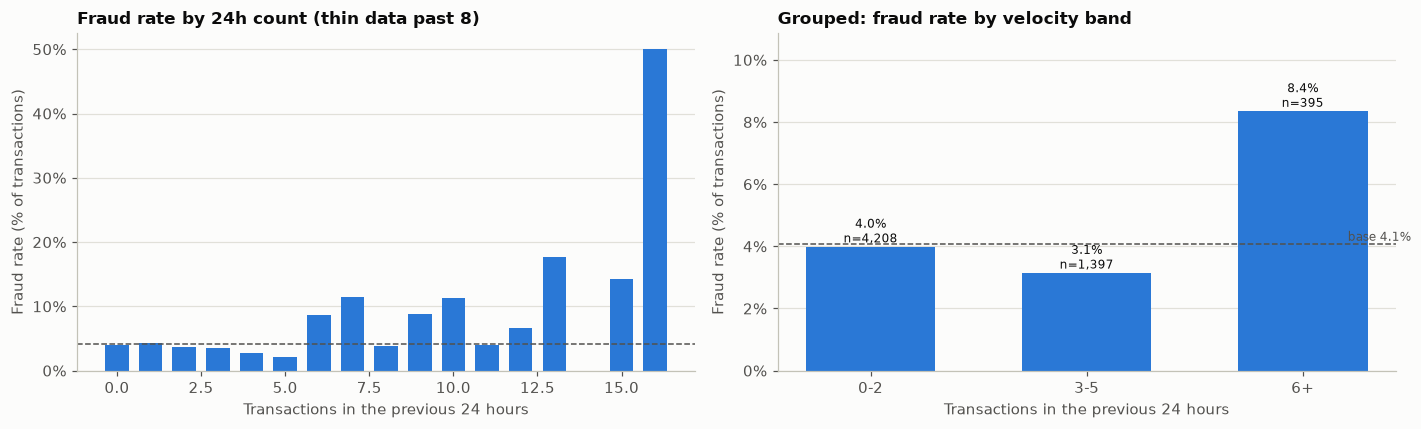

,n,frauds,rate,lift_vs_base,share_of_fraud
velocity_band,,,,,
0-2,4208,168,0.040,0.978,0.686
3-5,1397,44,0.031,0.771,0.180
6+,395,33,0.084,2.046,0.135


In [69]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
g = rate_table("txn_count_prev_24h")
axes[0].bar(g.index, g["rate"], color=BLUE, width=0.7)
axes[0].axhline(BASE, color=INK2, ls="--", lw=1)
axes[0].set_xlabel("Transactions in the previous 24 hours"); axes[0].set_ylabel("Fraud rate (% of transactions)"); axes[0].set_title("Fraud rate by 24h count (thin data past 8)")
pct_axis(axes[0])
rate_bar(axes[1], "velocity_band", "Grouped: fraud rate by velocity band")
plt.tight_layout(); plt.show()
display(rate_table("velocity_band").round(3))

**Reading:** Not a simple "more = riskier". Fraud rate is flat or slightly *below* base for 0-5 prior transactions, then jumps for **6+ (about 8% over ~395 transactions, 2x base)**. Individual counts above 8 are too small to read (the zigzag is noise), which is why I grouped them. Velocity is a **threshold/burst signal**, not a linear one, which hints that a tree-based model or a rule with a cutoff suits it better than a linear model.

### Q5. Does time of day, weekday, or account age matter?

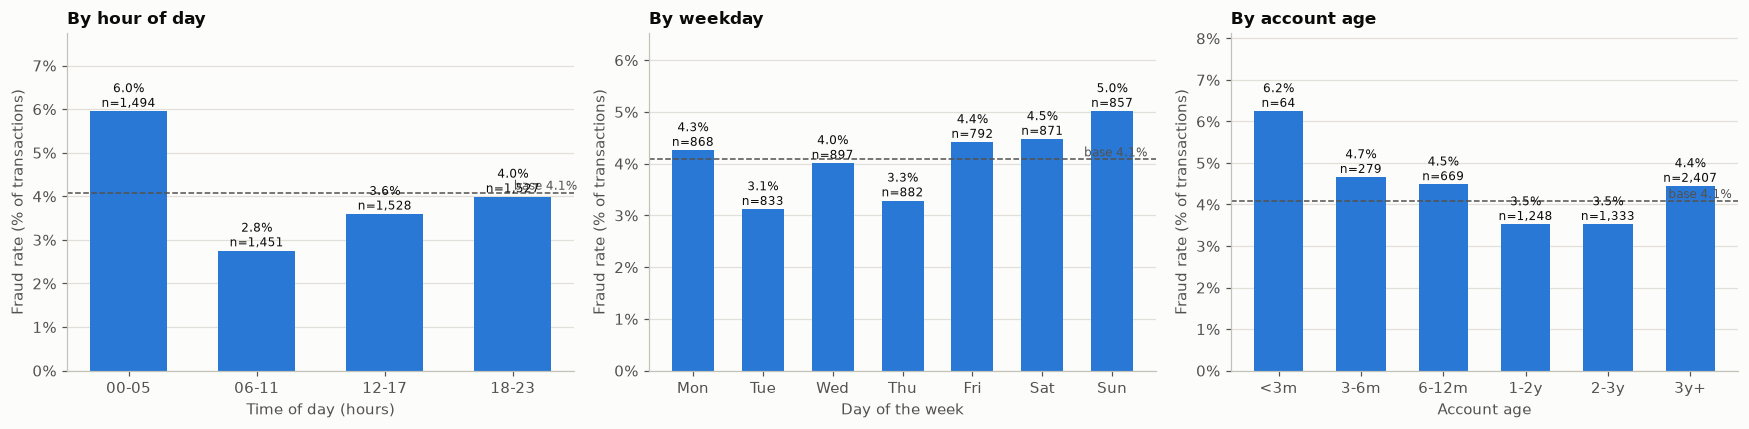

,n,frauds,rate,lift_vs_base,share_of_fraud
hour_block,,,,,
00-05,1494,89,0.060,1.459,0.363
06-11,1451,40,0.028,0.675,0.163
12-17,1528,55,0.036,0.882,0.224
18-23,1527,61,0.040,0.978,0.249


,n,frauds,rate,lift_vs_base,share_of_fraud
age_band,,,,,
<3m,64,4,0.062,1.531,0.016
3-6m,279,13,0.047,1.141,0.053
6-12m,669,30,0.045,1.098,0.122
1-2y,1248,44,0.035,0.863,0.180
2-3y,1333,47,0.035,0.863,0.192
3y+,2407,107,0.044,1.089,0.437


In [70]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
rate_bar(axes[0], "hour_block", "By hour of day")
rate_bar(axes[1], "weekday", "By weekday", order=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
rate_bar(axes[2], "age_band", "By account age")
plt.tight_layout(); plt.show()
display(rate_table("hour_block").round(3))
display(rate_table("age_band").round(3))

**Reading:**
- **Night (00-05) stands out:** 6.0% vs 2.8%-4.0% in the other blocks. It holds 36% of all fraud from 25% of traffic (about 1.5x base). A useful secondary signal.
- **Weekday:** Sunday is slightly higher (5.0%) and Tuesday lowest (3.1%), but with ~850 rows per day this is within noise.
- **Account age:** no clear pattern. Brand-new accounts (<3m) show 6.2% but that is only 64 transactions (4 frauds), too few to conclude. Fraud is **not** concentrated in new accounts here.

### Q6. Is the pattern stable over time, and do customers repeat?

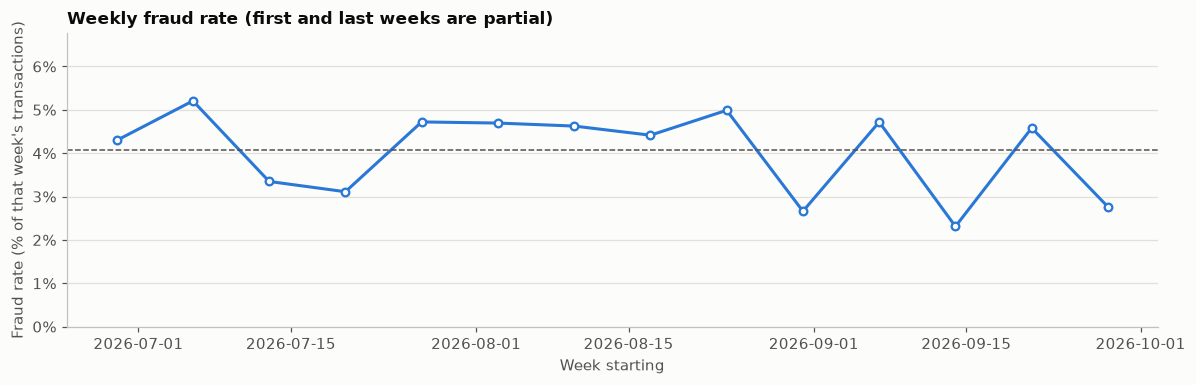

Customers with >=1 fraud: 212 of 949
Customers by number of frauds:
is_fraud
1    181
2     29
3      2


In [71]:
weekly = eda.groupby("week")["is_fraud"].agg(n="size", rate="mean")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(weekly.index, weekly["rate"], color=BLUE, lw=2, marker="o", ms=5, mfc=SURF, mew=1.5)
ax.axhline(BASE, color=INK2, ls="--", lw=1)
ax.set_ylim(0, weekly["rate"].max() * 1.3)
pct_axis(ax)
ax.set_xlabel("Week starting"); ax.set_ylabel("Fraud rate (% of that week's transactions)")
ax.set_title("Weekly fraud rate (first and last weeks are partial)")
plt.tight_layout(); plt.show()

fraud_per_cust = eda.groupby("customer_id")["is_fraud"].sum()
print("Customers with >=1 fraud:", (fraud_per_cust > 0).sum(), "of", len(fraud_per_cust))
print("Customers by number of frauds:")
print(fraud_per_cust[fraud_per_cust > 0].value_counts().sort_index().to_string())

**Reading:** The weekly rate moves between ~2% and ~5% around the 4.1% base with **no trend or drift**, so a single static rule/model is reasonable and there is no obvious regime change. Fraud rarely repeats per customer (181 of 212 affected customers have exactly one), so customer ID is not a useful signal. **But** each customer appears in several rows, so for modelling we should split train/test by time (or by customer) rather than by random rows, to avoid leakage.

### Q7. How far can simple stacked rules go? (precision vs. recall)
Count of six risk signals fire on a transaction: new device, new beneficiary, 2+ failed logins, international card, amount 3x+ usual, 6+ transactions in 24h.
*(The thresholds are chosen from the EDA above on this same data. The model step will validate on a held-out period.)*

,alerts,alerts_%_of_txns,frauds_caught,precision,recall,false_alarms_per_fraud
alert_if_flags>=,,,,,,
0,6000,1.000,245,0.041,1.000,23.490
1,2131,0.355,174,0.082,0.710,11.247
2,373,0.062,59,0.158,0.241,5.322
3,38,0.006,14,0.368,0.057,1.714
4,1,0.000,1,1.000,0.004,0.000


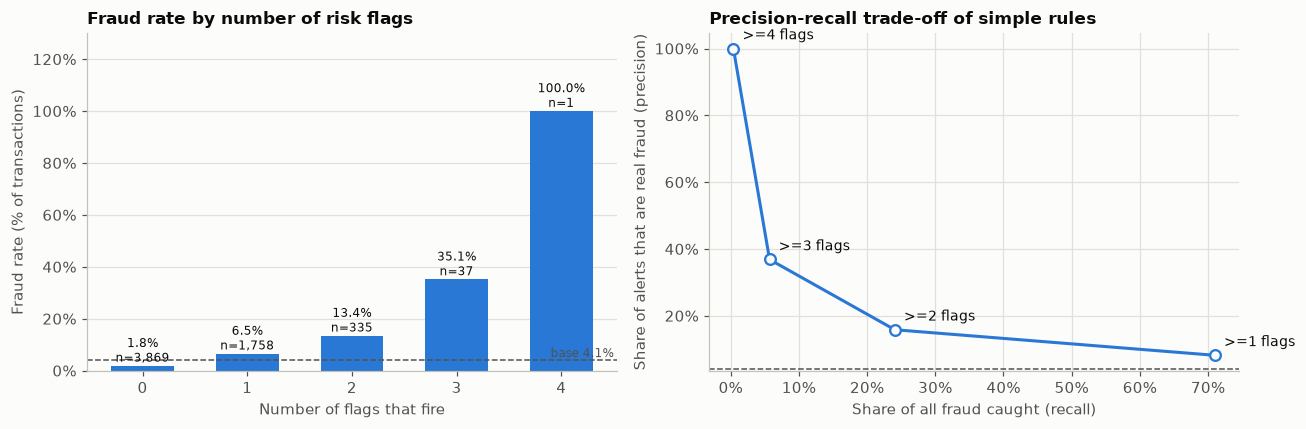

In [72]:
eda["n_flags"] = (eda["new_device_flag"] + eda["new_beneficiary_flag"]
                  + (eda["failed_login_attempts_prev_24h"] >= 2).astype(int)
                  + eda["international_card_flag"]
                  + (eda["amt_ratio"] >= 3).astype(int)
                  + (eda["txn_count_prev_24h"] >= 6).astype(int))

total_fraud = eda["is_fraud"].sum()
rows = []
for k in range(0, 5):
    flagged = eda[eda["n_flags"] >= k]
    tp = flagged["is_fraud"].sum()
    rows.append({"alert_if_flags>=": k, "alerts": len(flagged), "alerts_%_of_txns": len(flagged) / len(eda),
                 "frauds_caught": tp, "precision": tp / len(flagged), "recall": tp / total_fraud,
                 "false_alarms_per_fraud": (len(flagged) - tp) / tp})
rules = pd.DataFrame(rows).set_index("alert_if_flags>=")
display(rules.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rate_bar(axes[0], "n_flags", "Fraud rate by number of risk flags")
axes[0].set_xlabel("Number of flags that fire")
r = rules.loc[1:4]
axes[1].plot(r["recall"], r["precision"], color=BLUE, lw=2, marker="o", ms=7, mfc=SURF, mew=1.5)
for k, row in r.iterrows():
    axes[1].annotate(f">={k} flags", (row["recall"], row["precision"]), textcoords="offset points", xytext=(6, 6), fontsize=9)
axes[1].axhline(BASE, color=INK2, ls="--", lw=1)
axes[1].set_xlabel("Share of all fraud caught (recall)"); axes[1].set_ylabel("Share of alerts that are real fraud (precision)")
axes[1].set_title("Precision-recall trade-off of simple rules")
pct_axis(axes[1], "y"); pct_axis(axes[1], "x")
axes[1].grid(axis="x", color=GRID)
plt.tight_layout(); plt.show()

### EDA summary: what this means for the fraud team
| Question | Answer |
|---|---|
| Where is fraud? | Spread across all types/channels (2.4%-4.7%); **type/channel alone is a weak filter**. |
| Strongest signals | **New device** (~3.3x base), **new beneficiary** (~2.6x), **amount 5x+ above the customer's norm** (~2.5-3.5x), **6+ transactions in 24h** (~2x), **night hours** (~1.5x). |
| Weak / unusable | Raw amount, weekday, account age, international card (n=48), failed logins (mild). |
| Stability | No weekly drift; fraud rarely repeats per customer. |
| Stacking signals | Precision climbs steeply with the number of flags (1.8% at 0 flags, 6.5% at 1, 13% at 2, 35% at 3+), but **recall falls quickly**: ~29% of frauds fire no flag at all. |

**Implications for modelling:**
1. **Precision vs. recall is a real trade-off.** High-precision alerts (3+ flags) catch only a small share of fraud. A score that *ranks* transactions lets the ops team choose how many to review per day (a **review-capacity cut-off**) instead of a fixed rule.
2. Engineer **amount / 30d average** (log), a **night flag** and a **velocity burst (6+)**, and let the model combine them with the device/beneficiary flags. Signals stack, so interactions matter.
3. Use a **time-based split** (e.g. train Jul-Aug, test Sep) and report precision@top-N alerts, PR-AUC and recall at fixed precision, **not accuracy** (always predicting "legit" is 96% accurate).
4. About 29% of fraud has no visible signal in these features, so expect a recall ceiling and say so openly.

## 3. Outlier analysis
In fraud data an outlier may be exactly the thing we want to catch, so the goal here is not to delete them. For each numeric column we ask:
1. How many rows are statistical outliers (IQR rule: beyond 1.5 x IQR from the quartiles)?
2. Are they data errors, or real behaviour?
3. Is the fraud rate among outliers different from normal rows?

Amount-type columns are very right-skewed, so the IQR rule is applied on a **log10 scale** (otherwise it flags a large share of normal rows). Counts and account age are used as-is.

In [73]:
outlier_specs = [
    ("transaction_amount_pkr", True),
    ("avg_txn_amount_prev_30d_pkr", True),
    ("amt_ratio", True),
    ("txn_count_prev_24h", False),
    ("account_age_days", False),
]

rows, outlier_masks = [], {}
for col, use_log in outlier_specs:
    s = np.log10(eda[col]) if use_log else eda[col].astype(float)
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < lo) | (s > hi)
    outlier_masks[col] = mask
    lo_v, hi_v = (10 ** lo, 10 ** hi) if use_log else (max(lo, eda[col].min()), hi)
    rows.append({
        "column": col, "lower_fence": round(lo_v, 2), "upper_fence": round(hi_v, 2),
        "low_outliers": int((s < lo).sum()), "high_outliers": int((s > hi).sum()),
        "outlier_%": round(mask.mean() * 100, 1),
        "fraud_rate_outliers_%": round(eda.loc[mask, "is_fraud"].mean() * 100, 1) if mask.any() else np.nan,
        "fraud_rate_normal_%": round(eda.loc[~mask, "is_fraud"].mean() * 100, 1),
        "lift_vs_base": round(eda.loc[mask, "is_fraud"].mean() / BASE, 2) if mask.any() else np.nan,
        "share_of_all_fraud_%": round(eda.loc[mask, "is_fraud"].sum() / eda["is_fraud"].sum() * 100, 1),
    })
outlier_summary = pd.DataFrame(rows).set_index("column")
display(outlier_summary)

# failed logins: IQR is degenerate (75% of rows are 0, so IQR = 0); use a business cut-off instead
fl = eda["failed_login_attempts_prev_24h"] >= 3
print("Failed logins >= 3:", fl.sum(), "rows | fraud rate", f"{eda.loc[fl, 'is_fraud'].mean():.1%}",
      "vs", f"{eda.loc[~fl, 'is_fraud'].mean():.1%}", "otherwise")

,lower_fence,upper_fence,low_outliers,high_outliers,outlier_%,fraud_rate_outliers_%,fraud_rate_normal_%,lift_vs_base,share_of_all_fraud_%
column,,,,,,,,,
transaction_amount_pkr,206.57,123515.58,21,49,1.2,10.0,4.0,2.45,2.9
avg_txn_amount_prev_30d_pkr,641.26,39397.84,18,23,0.7,4.9,4.1,1.19,0.8
amt_ratio,0.09,11.12,17,77,1.6,12.8,3.9,3.13,4.9
txn_count_prev_24h,0.00,6.00,0,337,5.6,8.3,3.8,2.03,11.4
account_age_days,37.00,2651.50,0,0,0.0,NaN,4.1,NaN,0.0


Failed logins >= 3: 149 rows | fraud rate 7.4% vs 4.0% otherwise


C:\Users\mohib\AppData\Local\Temp\ipykernel_13448\198980654.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, tick_labels=["Legitimate", "Fraud"],
C:\Users\mohib\AppData\Local\Temp\ipykernel_13448\198980654.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, tick_labels=["Legitimate", "Fraud"],
C:\Users\mohib\AppData\Local\Temp\ipykernel_13448\198980654.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, tick_labels=["Legitimate", "Fraud"],
C:\Users\mohi

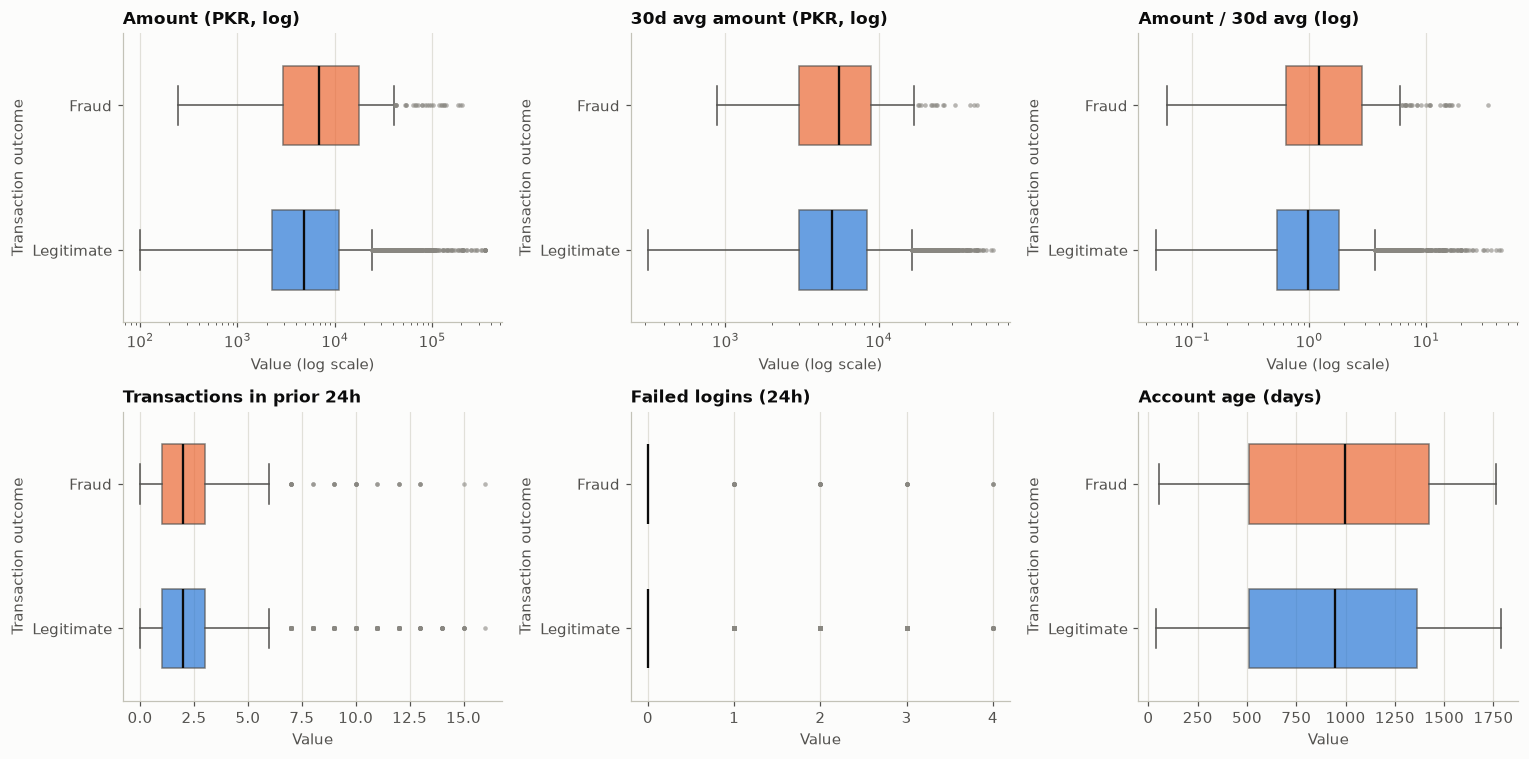

In [74]:
# Boxplots: legit vs fraud for each numeric column (outlier points shown as dots)
cols = [("transaction_amount_pkr", True, "Amount (PKR, log)"),
        ("avg_txn_amount_prev_30d_pkr", True, "30d avg amount (PKR, log)"),
        ("amt_ratio", True, "Amount / 30d avg (log)"),
        ("txn_count_prev_24h", False, "Transactions in prior 24h"),
        ("failed_login_attempts_prev_24h", False, "Failed logins (24h)"),
        ("account_age_days", False, "Account age (days)")]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, use_log, title) in zip(axes.ravel(), cols):
    data = [eda.loc[eda["is_fraud"] == 0, col], eda.loc[eda["is_fraud"] == 1, col]]
    bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, tick_labels=["Legitimate", "Fraud"],
                    flierprops=dict(marker="o", markersize=3, markerfacecolor=MUTED, markeredgecolor="none", alpha=0.6),
                    medianprops=dict(color=INK, linewidth=1.5), whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
    for patch, color in zip(bp["boxes"], [BLUE, ORANGE]):
        patch.set_facecolor(color); patch.set_alpha(0.7); patch.set_edgecolor(INK2)
    if use_log:
        ax.set_xscale("log")
    ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID)
    ax.set_title(title); ax.set_xlabel("Value (log scale)" if use_log else "Value"); ax.set_ylabel("Transaction outcome")
plt.tight_layout(); plt.show()

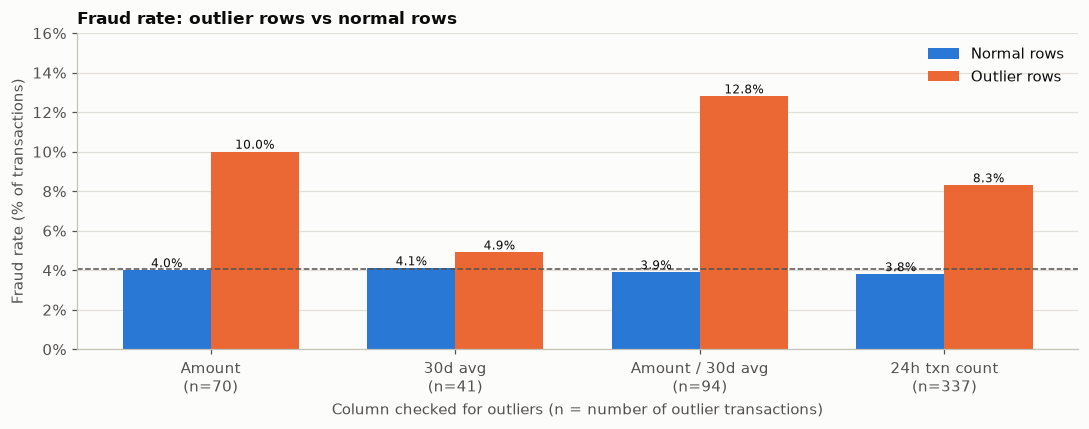

In [75]:
plot_rows = outlier_summary.dropna(subset=["fraud_rate_outliers_%"])
labels = ["Amount", "30d avg", "Amount / 30d avg", "24h txn count"]
ns = outlier_summary.loc[plot_rows.index, ["low_outliers", "high_outliers"]].sum(axis=1).astype(int)
tick_labels = [f"{lab}\n(n={n})" for lab, n in zip(labels, ns)]

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(plot_rows)); w = 0.36
b1 = ax.bar(x - w / 2, plot_rows["fraud_rate_normal_%"] / 100, w, color=BLUE, label="Normal rows")
b2 = ax.bar(x + w / 2, plot_rows["fraud_rate_outliers_%"] / 100, w, color=ORANGE, label="Outlier rows")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.1%}",
                ha="center", va="bottom", fontsize=8)

ax.axhline(BASE, color=INK2, ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels(tick_labels)
ax.set_ylim(0, plot_rows["fraud_rate_outliers_%"].max() / 100 * 1.25)
pct_axis(ax); ax.legend(frameon=False)
ax.set_xlabel("Column checked for outliers (n = number of outlier transactions)"); ax.set_ylabel("Fraud rate (% of transactions)")
ax.set_title("Fraud rate: outlier rows vs normal rows")
plt.tight_layout(); plt.show()

In [76]:
# Look at individual extreme rows: are they reasonable?
cols_show = ["transaction_type", "transaction_amount_pkr", "avg_txn_amount_prev_30d_pkr", "amt_ratio",
             "txn_count_prev_24h", "new_device_flag", "new_beneficiary_flag", "is_fraud"]
print("Top 8 by amount relative to customer norm:")
display(eda.nlargest(8, "amt_ratio")[cols_show].round(1))
print("Top 8 by 24h transaction count:")
display(eda.nlargest(8, "txn_count_prev_24h")[cols_show].round(1))
print("Smallest 8 amounts (possible test/micro transactions):")
display(eda.nsmallest(8, "transaction_amount_pkr")[cols_show].round(1))

Top 8 by amount relative to customer norm:


,transaction_type,transaction_amount_pkr,avg_txn_amount_prev_30d_pkr,amt_ratio,txn_count_prev_24h,new_device_flag,new_beneficiary_flag,is_fraud
2624,Bill Payment,350000,8026,43.6,5,1,0,0
4822,Raast Transfer,269239,6429,41.9,12,0,0,0
4247,Raast Transfer,74965,1872,40.0,2,0,0,0
2563,Card Purchase,106693,2960,36.0,0,0,0,0
3671,Card Purchase,42085,1234,34.1,0,0,0,1
1160,Raast Transfer,209356,6294,33.3,2,0,1,0
5529,Card Purchase,50578,1623,31.2,1,0,0,0
4783,Card Purchase,117248,3817,30.7,4,0,0,0


Top 8 by 24h transaction count:


,transaction_type,transaction_amount_pkr,avg_txn_amount_prev_30d_pkr,amt_ratio,txn_count_prev_24h,new_device_flag,new_beneficiary_flag,is_fraud
225,Raast Transfer,1763,1787,1.0,16,0,1,1
4757,Card Purchase,5362,2447,2.2,16,0,0,0
500,IBFT Transfer,26392,6747,3.9,15,0,0,0
567,Card Purchase,1585,7786,0.2,15,0,0,0
1381,Card Purchase,34491,23290,1.5,15,0,0,0
2984,Raast Transfer,2771,3121,0.9,15,0,0,0
3987,IBFT Transfer,4460,7381,0.6,15,1,1,1
4028,Card Purchase,735,5210,0.1,15,0,0,0


Smallest 8 amounts (possible test/micro transactions):


,transaction_type,transaction_amount_pkr,avg_txn_amount_prev_30d_pkr,amt_ratio,txn_count_prev_24h,new_device_flag,new_beneficiary_flag,is_fraud
1336,Card Purchase,100,2047,0.0,2,0,0,0
5483,Bill Payment,100,1440,0.1,4,0,0,0
1783,Raast Transfer,111,972,0.1,3,0,0,0
4633,Raast Transfer,113,822,0.1,1,0,0,0
4070,Bill Payment,114,1052,0.1,2,0,0,0
1683,Card Purchase,118,2114,0.1,0,0,0,0
1745,Raast Transfer,123,2437,0.1,1,0,0,0
5164,Card Purchase,128,1124,0.1,1,0,0,0


### Outlier findings
- **No data errors found.** Extreme values are internally consistent: no negative or impossible values, and the high-ratio / high-velocity rows look like genuine behaviour. The only artificial feature is the **PKR 350,000 ceiling** (9 rows, all legitimate).
- **Outliers are rare except for velocity:** only 1-2% of rows are outliers on amount, 30d average and ratio, whereas 24h transaction count flags ~6% (337 rows with more than 6 prior transactions).
- **Outliers are riskier than normal rows, but not dramatically:**
  - *Amount vs customer's norm*: **12.8% fraud** among outliers vs 3.9% normal (about 3x base), but only 94 rows and 12 frauds.
  - *24h transaction count*: 8.3% vs 3.8% (about 2x base), and the **largest outlier group (28 frauds, 11% of all fraud)**.
  - *Raw amount*: 10.0% vs 4.0% on 70 rows (7 frauds), small and noisy.
  - *30d average*: 4.9% vs 4.1%, essentially no signal.
  - *Account age*: no outliers.
- **Failed logins** have a degenerate IQR (most rows are 0), so I used a business cut-off: 3+ failed logins gives 7.4% fraud (149 rows) vs 4.0%.
- **Small amounts are not a hidden fraud pattern:** the smallest amounts (e.g. under PKR 206, 21 rows) contain no fraud.

**Decision:** **keep all rows.** Removing or clipping outliers would throw away exactly the high-risk transactions, and even so they explain only a minority of fraud (<12% each). Instead, reduce their influence on the model by using **log amounts, the amount / 30d ratio, and capped counts**, and by using a tree-based models which are not sensitive to extreme values. Outlier-ness is useful as a feature on its own (e.g. "ratio above 11x", "more than 6 prior transactions").

## 4. Modelling: random forest
**Approach and why**
- **Model:** Random forest. It handles skewed amounts/counts and threshold effects (e.g. "6+ transactions") without scaling, captures interactions between signals, and is robust to the outliers I decided to keep.
- **Split:** by **time**, not randomly. Train on July-August, test on September, which mimics deploying on future data. (811 customers appear in both periods, so a random split would leak customer behaviour.)
- **No resampling.** Training keeps the real ~4% fraud rate, so scores stay honest.
- **Features:** log amount, log 30d average, log amount-to-average ratio, 24h count, failed logins, account age, the three flags, hour/night/weekend, and one-hot type and channel. No IDs and nothing from the outcome.
- **Evaluation:** PR-AUC and **precision / recall when reviewers only look at the top N% of scores**, which matches how an ops team with limited capacity would use it. No accuracy. A bootstrap interval is shown because the test month has only 70 frauds.
- **Baselines to beat:** random ranking (the base rate) and the simple risk-flag rule from the EDA.

In [77]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.inspection import permutation_importance

# ---- Feature table (built from the cleaned data; no IDs, no outcome, nothing from the future) ----
def build_features(d):
    X = pd.DataFrame(index=d.index)
    X["log_amount"] = np.log10(d["transaction_amount_pkr"])
    X["log_avg_30d"] = np.log10(d["avg_txn_amount_prev_30d_pkr"])
    X["log_amt_ratio"] = np.log10(d["transaction_amount_pkr"] / d["avg_txn_amount_prev_30d_pkr"])
    X["txn_count_prev_24h"] = d["txn_count_prev_24h"]
    X["failed_logins_24h"] = d["failed_login_attempts_prev_24h"]
    X["account_age_days"] = d["account_age_days"]
    X["new_device"] = d["new_device_flag"]
    X["new_beneficiary"] = d["new_beneficiary_flag"]
    X["intl_card"] = d["international_card_flag"]
    hour = d["transaction_datetime"].dt.hour
    X["hour"] = hour
    X["is_night"] = (hour <= 5).astype(int)
    X["is_weekend"] = (d["transaction_datetime"].dt.dayofweek >= 5).astype(int)
    X = X.join(pd.get_dummies(d["transaction_type"], prefix="type", dtype=int))
    X = X.join(pd.get_dummies(d["channel"], prefix="chan", dtype=int))
    return X

model_df = fraud_df.sort_values("transaction_datetime").reset_index(drop=True)
X_all, y_all = build_features(model_df), model_df["is_fraud"]

# ---- Time-based split: train on Jul-Aug, test on Sep (simulates deploying on future data) ----
cutoff = pd.Timestamp("2026-09-01")
train_mask = model_df["transaction_datetime"] < cutoff
X_train, y_train = X_all[train_mask], y_all[train_mask]
X_test, y_test = X_all[~train_mask], y_all[~train_mask]

print(f"Train: {len(X_train):,} rows, {y_train.sum()} frauds ({y_train.mean():.2%})")
print(f"Test : {len(X_test):,} rows, {y_test.sum()} frauds ({y_test.mean():.2%})")
print("Customers in both train and test:",
      len(set(model_df.loc[train_mask, "customer_id"]) & set(model_df.loc[~train_mask, "customer_id"])))
print("Features:", X_all.shape[1])

Train: 4,024 rows, 175 frauds (4.35%)
Test : 1,976 rows, 70 frauds (3.54%)
Customers in both train and test: 811
Features: 21


C:\Users\mohib\AppData\Local\Temp\ipykernel_13448\3657751559.py:20: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  X["is_weekend"] = (d["transaction_datetime"].dt.dayofweek >= 5).astype(int)


In [78]:
# ---- Evaluation helpers: precision / recall when reviewers only look at the top-N% highest scores ----
def alert_table(y_true, scores, pcts=(0.01, 0.02, 0.05, 0.10, 0.20)):
    y_true = np.asarray(y_true); order = np.argsort(-np.asarray(scores), kind="stable")
    out = []
    for p in pcts:
        k = max(1, int(round(len(y_true) * p)))
        tp = y_true[order[:k]].sum()
        out.append({"review_top_%": f"{p:.0%}", "alerts": k, "frauds_caught": int(tp),
                    "precision": tp / k, "recall": tp / y_true.sum(),
                    "lift_vs_random": (tp / k) / y_true.mean()})
    return pd.DataFrame(out).set_index("review_top_%")

def bootstrap_ci(y_true, scores, metric, n=300, seed=0):
    rng = np.random.default_rng(seed); y_true = np.asarray(y_true); scores = np.asarray(scores); vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].sum() == 0:
            continue
        vals.append(metric(y_true[idx], scores[idx]))
    return np.percentile(vals, [2.5, 97.5])

def summarize(name, y_true, scores):
    ap, auc = average_precision_score(y_true, scores), roc_auc_score(y_true, scores)
    lo, hi = bootstrap_ci(y_true, scores, average_precision_score)
    print(f"{name:<34} PR-AUC {ap:.3f} (95% CI {lo:.3f}-{hi:.3f}) | ROC-AUC {auc:.3f} | base rate {np.mean(y_true):.3f}")
    return ap

In [79]:
# ---- Baselines the model has to beat ----
# 1) Random ranking = the base rate. 2) The simple stacked-flag rule from the EDA (no training needed).
test_rows = model_df.loc[~train_mask]
rule_score = (test_rows["new_device_flag"] + test_rows["new_beneficiary_flag"]
              + (test_rows["failed_login_attempts_prev_24h"] >= 2).astype(int) + test_rows["international_card_flag"]
              + (test_rows["transaction_amount_pkr"] / test_rows["avg_txn_amount_prev_30d_pkr"] >= 3).astype(int)
              + (test_rows["txn_count_prev_24h"] >= 6).astype(int)).values
rng = np.random.default_rng(1)
rule_score_tb = rule_score + rng.uniform(0, 0.01, len(rule_score))   # tiny jitter to break ties randomly

summarize("Rule: number of risk flags", y_test.values, rule_score_tb)

Rule: number of risk flags         PR-AUC 0.119 (95% CI 0.073-0.206) | ROC-AUC 0.715 | base rate 0.035


0.11935907768720505

In [80]:
# ---- Random forest: with and without class weighting (compare, don't assume) ----
rf_params = dict(n_estimators=500, min_samples_leaf=10, max_features="sqrt", n_jobs=-1, random_state=42)
rf_plain = RandomForestClassifier(**rf_params).fit(X_train, y_train)
rf_bal = RandomForestClassifier(class_weight="balanced_subsample", **rf_params).fit(X_train, y_train)

scores = {"RF (no class weight)": rf_plain.predict_proba(X_test)[:, 1],
          "RF (balanced_subsample)": rf_bal.predict_proba(X_test)[:, 1]}
for name, s in scores.items():
    summarize(name, y_test.values, s)

RF (no class weight)               PR-AUC 0.141 (95% CI 0.081-0.237) | ROC-AUC 0.703 | base rate 0.035


RF (balanced_subsample)            PR-AUC 0.109 (95% CI 0.069-0.172) | ROC-AUC 0.701 | base rate 0.035


In [81]:
print("Rule baseline - review top N% of Sept transactions:")
display(alert_table(y_test, rule_score_tb).round(3))
for name, s in scores.items():
    print(name)
    display(alert_table(y_test, s).round(3))

Rule baseline - review top N% of Sept transactions:


,alerts,frauds_caught,precision,recall,lift_vs_random
review_top_%,,,,,
1%,20,6,0.300,0.086,8.469
2%,40,11,0.275,0.157,7.763
5%,99,15,0.152,0.214,4.277
10%,198,22,0.111,0.314,3.137
20%,395,31,0.078,0.443,2.215


RF (no class weight)


,alerts,frauds_caught,precision,recall,lift_vs_random
review_top_%,,,,,
1%,20,7,0.350,0.100,9.880
2%,40,11,0.275,0.157,7.763
5%,99,15,0.152,0.214,4.277
10%,198,21,0.106,0.300,2.994
20%,395,30,0.076,0.429,2.144


RF (balanced_subsample)


,alerts,frauds_caught,precision,recall,lift_vs_random
review_top_%,,,,,
1%,20,6,0.300,0.086,8.469
2%,40,10,0.250,0.143,7.057
5%,99,14,0.141,0.200,3.992
10%,198,19,0.096,0.271,2.709
20%,395,33,0.084,0.471,2.358


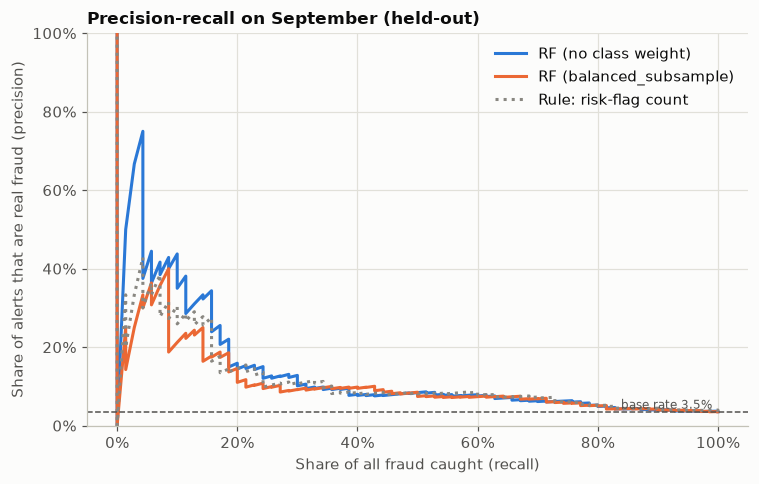

In [82]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for (name, s), color in zip(scores.items(), [BLUE, ORANGE]):
    pr, rc, _ = precision_recall_curve(y_test, s)
    ax.plot(rc, pr, color=color, lw=2, label=name)
pr, rc, _ = precision_recall_curve(y_test, rule_score_tb)
ax.plot(rc, pr, color=MUTED, lw=2, ls=":", label="Rule: risk-flag count")
ax.axhline(y_test.mean(), color=INK2, ls="--", lw=1)
ax.text(0.99, y_test.mean(), f" base rate {y_test.mean():.1%}", ha="right", va="bottom", fontsize=8, color=INK2)
ax.set_xlabel("Share of all fraud caught (recall)"); ax.set_ylabel("Share of alerts that are real fraud (precision)")
ax.set_title("Precision-recall on September (held-out)"); ax.set_ylim(0, 1.0)
pct_axis(ax, "y"); pct_axis(ax, "x"); ax.grid(axis="x", color=GRID); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

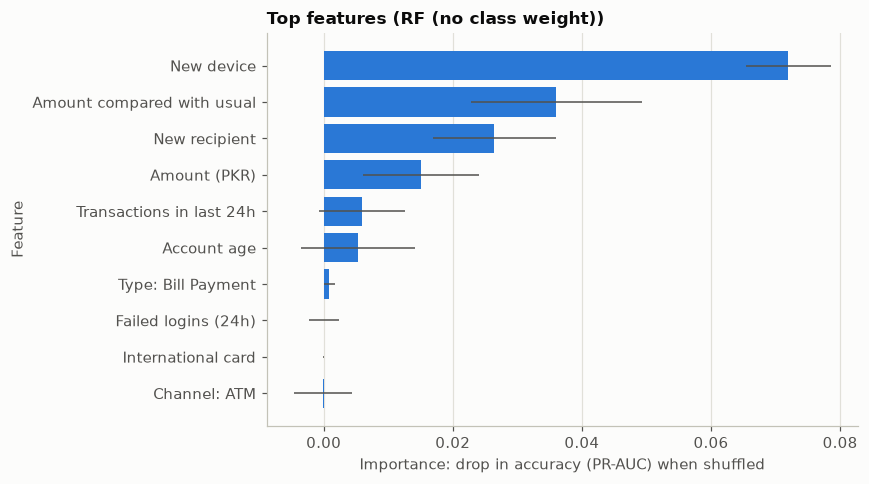

Model used for importance: RF (no class weight)


In [83]:
# Permutation importance on the held-out month: how much does PR-AUC drop if a feature is shuffled?
best_name = max(scores, key=lambda k: average_precision_score(y_test, scores[k]))
best_model = {"RF (no class weight)": rf_plain, "RF (balanced_subsample)": rf_bal}[best_name]
pi = permutation_importance(best_model, X_test, y_test, scoring="average_precision", n_repeats=20, random_state=0, n_jobs=1)
imp = pd.DataFrame({"mean_drop": pi.importances_mean, "std": pi.importances_std}, index=X_test.columns).sort_values("mean_drop")
top = imp.tail(10)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(nice_names(top.index), top["mean_drop"], xerr=top["std"], color=BLUE, ecolor=INK2, error_kw=dict(lw=1))
ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID)
ax.set_xlabel("Importance: drop in accuracy (PR-AUC) when shuffled"); ax.set_ylabel("Feature"); ax.set_title(f"Top features ({best_name})")
plt.tight_layout(); plt.show()
print("Model used for importance:", best_name)

In [84]:
# Is the result stable? Re-train on expanding windows and test on each following month/half-month.
splits = [("train Jul -> test Aug", "2026-08-01", "2026-09-01"), ("train Jul-Aug -> test Sep", "2026-09-01", "2026-10-01")]
rows = []
for label, start, end in splits:
    tr = model_df["transaction_datetime"] < pd.Timestamp(start)
    te = (model_df["transaction_datetime"] >= pd.Timestamp(start)) & (model_df["transaction_datetime"] < pd.Timestamp(end))
    m = RandomForestClassifier(**rf_params).fit(X_all[tr], y_all[tr])
    s = m.predict_proba(X_all[te])[:, 1]
    at = alert_table(y_all[te], s, pcts=(0.05,))
    rows.append({"split": label, "train_frauds": int(y_all[tr].sum()), "test_frauds": int(y_all[te].sum()),
                 "PR-AUC": average_precision_score(y_all[te], s), "base_rate": y_all[te].mean(),
                 "precision@top5%": at["precision"].iloc[0], "recall@top5%": at["recall"].iloc[0]})
display(pd.DataFrame(rows).set_index("split").round(3))

,train_frauds,test_frauds,PR-AUC,base_rate,precision@top5%,recall@top5%
split,,,,,,
train Jul -> test Aug,82,93,0.093,0.047,0.090,0.097
train Jul-Aug -> test Sep,175,70,0.141,0.035,0.152,0.214


### Modelling findings (first random forest)
**Results on held-out September (1,976 transactions, 70 frauds, 3.5% base rate):**

| Ranking method | PR-AUC (95% CI) | Precision at top 1% (20 alerts) | Precision at top 5% (99 alerts) | Recall at top 5% |
|---|---|---|---|---|
| Random | 0.035 | 3.5% | 3.5% | 5% |
| Risk-flag rule | 0.119 (0.073-0.206) | 30.0% | 15.2% | 21.4% |
| **Random forest** | **0.141 (0.081-0.237)** | **35.0%** | **15.2%** | **21.4%** |
| RF, balanced class weight | 0.109 (0.069-0.172) | 30.0% | 14.1% | 20.0% |

1. **The model is useful, but only moderately.** It ranks fraud about 4x better than random in PR-AUC, and the top 1% of alerts is about 35% precise (roughly 10x lift). Reviewing the top 5% yields about 1 real fraud in 7 alerts while catching about a fifth of all fraud.
2. **It does not clearly beat the simple rule.** The confidence intervals overlap almost completely, so with only 70 test frauds I **cannot claim** the forest is better than the stacked-flag rule. An honest conclusion is that most of the usable signal is already captured by a handful of simple, explainable flags.
3. **Class weighting did not help** (PR-AUC 0.109 vs 0.141, within noise but not better), which supports training on the natural class balance and choosing the threshold from review capacity.
4. **What drives the model:** `new_device` by a wide margin, then amount relative to the customer's norm (`log_amt_ratio`), `new_beneficiary` and raw amount. Failed logins, international card and channel add almost nothing. This matches the EDA.
5. **Stability caveat:** training on July only and testing on August gives PR-AUC 0.093 (about 2x its 4.7% base rate), weaker than the September result because only 82 frauds were available to learn from. Results will move with the test month, so I would treat the numbers above as a range, not exact.
6. **Ceiling:** about 29% of frauds fire none of our risk signals, and ROC-AUC is only about 0.70, so these features carry limited information. No amount of tuning is likely to change that much.

**What this means for the bank:** use the score to *prioritise* a review queue sized to analyst capacity (for example the top 1-2% daily), not as an automatic block. At the top 1-2% roughly 3 of 10 alerts are real fraud.

**Possible next steps:** compare against logistic regression and gradient boosting, tune the forest lightly (depth, leaf size) with time-based validation, and decide the final alert volume with the fraud team's review capacity.

## 5. Next technique: logistic regression
**Why this one:** the random forest did not clearly beat a simple rule, so the useful question is *does model complexity buy anything here?* Logistic regression is the natural test:
- it is **linear and explainable** (each feature gets a coefficient a fraud analyst can read), which is how risk teams usually prefer to work,
- it is fast, stable with only ~175 training frauds, and heavily regularisable (less overfitting),
- if it matches the forest, we can justify the simpler model.

Because it is linear I prepared the features accordingly: hour as sin/cos, a "6+ transactions" burst flag (the EDA showed a threshold effect), counts capped at 10, and standardised features. The regularisation strength C is tuned with **forward-chaining time validation inside the training period only**, so September stays untouched.

In [85]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Logistic regression is linear, so give it features in a linear-friendly form:
#  - hour -> sin/cos (23:00 and 00:00 are neighbours), - velocity threshold (the EDA showed a jump at 6+),
#  - scale everything so coefficients are comparable.
def lr_features(X):
    Z = X.drop(columns=["hour"]).copy()
    Z["hour_sin"] = np.sin(2 * np.pi * X["hour"] / 24)
    Z["hour_cos"] = np.cos(2 * np.pi * X["hour"] / 24)
    Z["burst_6plus"] = (X["txn_count_prev_24h"] >= 6).astype(int)
    Z["txn_count_prev_24h"] = X["txn_count_prev_24h"].clip(upper=10)
    return Z

Z_train, Z_test = lr_features(X_train), lr_features(X_test)

In [86]:
# Choose the regularisation strength C with forward-chaining time validation INSIDE the training period only
# (the September test set is never used for tuning).
train_dates = model_df.loc[train_mask, "transaction_datetime"].reset_index(drop=True)
folds = [("2026-07-15", "2026-08-01"), ("2026-08-01", "2026-08-16"), ("2026-08-16", "2026-09-01")]
Zt, yt = Z_train.reset_index(drop=True), y_train.reset_index(drop=True)

def make_lr(C, class_weight=None):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight=class_weight, max_iter=2000))

rows = []
for C in [0.0001, 0.001, 0.01, 0.1, 1, 10]:
    aps = []
    for start, end in folds:
        tr = train_dates < pd.Timestamp(start)
        va = (train_dates >= pd.Timestamp(start)) & (train_dates < pd.Timestamp(end))
        m = make_lr(C).fit(Zt[tr], yt[tr])
        aps.append(average_precision_score(yt[va], m.predict_proba(Zt[va])[:, 1]))
    rows.append({"C": C, "mean_PR-AUC": np.mean(aps), **{f"fold{i+1}": a for i, a in enumerate(aps)}})
tune = pd.DataFrame(rows).set_index("C")
display(tune.round(3))
best_C = tune["mean_PR-AUC"].idxmax()
print("Best C:", best_C)

,mean_PR-AUC,fold1,fold2,fold3
C,,,,
0.0001,0.144,0.187,0.081,0.165
0.0010,0.145,0.189,0.083,0.163
0.0100,0.144,0.193,0.087,0.152
0.1000,0.141,0.182,0.089,0.153
1.0000,0.139,0.172,0.090,0.155
10.0000,0.139,0.170,0.090,0.156


Best C: 0.001


In [87]:
lr_plain = make_lr(best_C).fit(Z_train, y_train)
lr_bal = make_lr(best_C, "balanced").fit(Z_train, y_train)
scores["Logistic regression"] = lr_plain.predict_proba(Z_test)[:, 1]
scores["Logistic regression (balanced)"] = lr_bal.predict_proba(Z_test)[:, 1]

for name in ["Logistic regression", "Logistic regression (balanced)"]:
    summarize(name, y_test.values, scores[name])
print()
display(alert_table(y_test, scores["Logistic regression"]).round(3))

Logistic regression                PR-AUC 0.122 (95% CI 0.071-0.201) | ROC-AUC 0.720 | base rate 0.035
Logistic regression (balanced)     PR-AUC 0.112 (95% CI 0.066-0.182) | ROC-AUC 0.713 | base rate 0.035



,alerts,frauds_caught,precision,recall,lift_vs_random
review_top_%,,,,,
1%,20,6,0.300,0.086,8.469
2%,40,9,0.225,0.129,6.351
5%,99,17,0.172,0.243,4.847
10%,198,24,0.121,0.343,3.422
20%,395,36,0.091,0.514,2.573


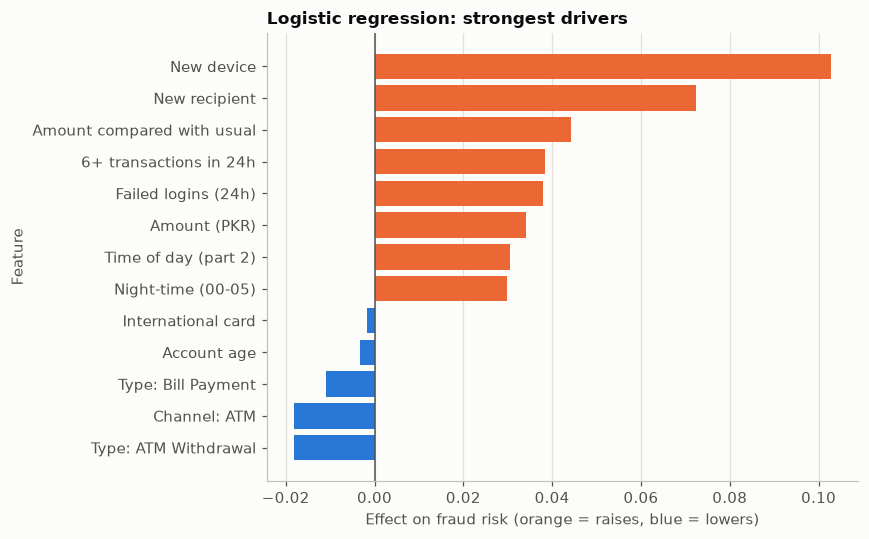

In [88]:
# Interpretable view: coefficients on standardised features (positive = raises fraud risk)
coefs = pd.Series(lr_plain[-1].coef_[0], index=Z_train.columns).sort_values()
show_coefs = pd.concat([coefs.head(5), coefs.tail(8)])
fig, ax = plt.subplots(figsize=(8, 5))
colors = [ORANGE if v > 0 else BLUE for v in show_coefs.values]
ax.barh(nice_names(show_coefs.index), show_coefs.values, color=colors)
ax.axvline(0, color=INK2, lw=1)
ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID)
ax.set_xlabel("Effect on fraud risk (orange = raises, blue = lowers)"); ax.set_ylabel("Feature")
ax.set_title("Logistic regression: strongest drivers")
plt.tight_layout(); plt.show()

### All techniques on one precision-recall plot

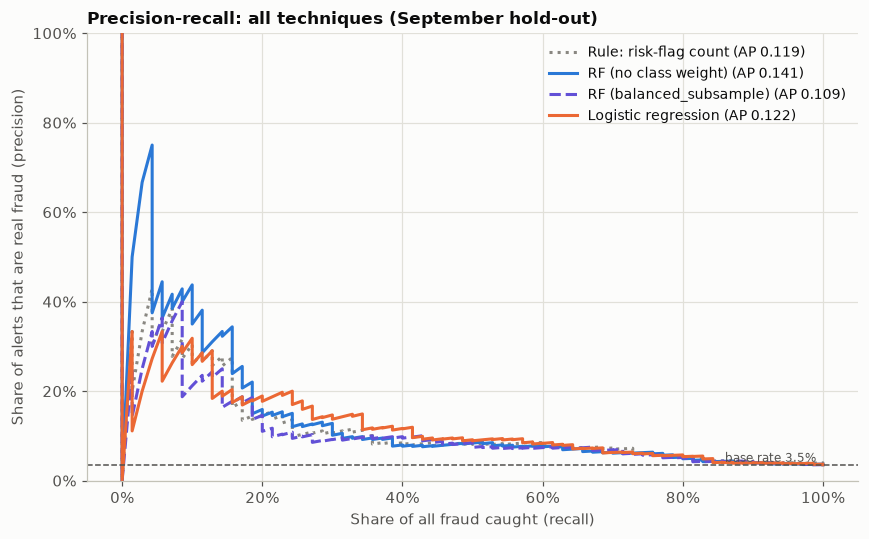

,PR-AUC,ROC-AUC,precision@top1%,precision@top5%,recall@top5%,recall@top10%
Rule: risk-flag count,0.119,0.715,0.30,0.152,0.214,0.314
RF (no class weight),0.141,0.703,0.35,0.152,0.214,0.300
RF (balanced_subsample),0.109,0.701,0.30,0.141,0.200,0.271
Logistic regression,0.122,0.720,0.30,0.172,0.243,0.343


In [89]:
# All techniques on one precision-recall plot (September hold-out)
curve_styles = {
    "Rule: risk-flag count": (rule_score_tb, MUTED, ":"),
    "RF (no class weight)": (scores["RF (no class weight)"], BLUE, "-"),
    "RF (balanced_subsample)": (scores["RF (balanced_subsample)"], "#6250d6", "--"),
    "Logistic regression": (scores["Logistic regression"], ORANGE, "-"),
}
fig, ax = plt.subplots(figsize=(8, 5))
for name, (s, color, ls) in curve_styles.items():
    pr, rc, _ = precision_recall_curve(y_test, s)
    ax.plot(rc, pr, color=color, ls=ls, lw=2, label=f"{name} (AP {average_precision_score(y_test, s):.3f})")
ax.axhline(y_test.mean(), color=INK2, ls="--", lw=1)
ax.text(0.99, y_test.mean(), f" base rate {y_test.mean():.1%}", ha="right", va="bottom", fontsize=8, color=INK2)
ax.set_xlabel("Share of all fraud caught (recall)"); ax.set_ylabel("Share of alerts that are real fraud (precision)"); ax.set_ylim(0, 1.0)
ax.set_title("Precision-recall: all techniques (September hold-out)")
pct_axis(ax, "y"); pct_axis(ax, "x"); ax.grid(axis="x", color=GRID); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

comparison = pd.DataFrame({
    name: {"PR-AUC": average_precision_score(y_test, s), "ROC-AUC": roc_auc_score(y_test, s),
           "precision@top1%": alert_table(y_test, s, pcts=(0.01,))["precision"].iloc[0],
           "precision@top5%": alert_table(y_test, s, pcts=(0.05,))["precision"].iloc[0],
           "recall@top5%": alert_table(y_test, s, pcts=(0.05,))["recall"].iloc[0],
           "recall@top10%": alert_table(y_test, s, pcts=(0.10,))["recall"].iloc[0]}
    for name, (s, _, _) in curve_styles.items()
}).T
display(comparison.round(3))

### Logistic regression findings
1. **It performs about as well as the random forest.** PR-AUC 0.122 (95% CI 0.071-0.201) vs 0.141 for the forest and 0.119 for the simple rule. All intervals overlap, so **we cannot separate the three on this data**. ROC-AUC is actually highest for logistic regression (0.720 vs 0.703).
2. **At review-capacity cut-offs it is competitive or better:** reviewing the top 5% (99 alerts) gives **17.2% precision and 24.3% recall** vs 15.2% / 21.4% for the forest and the rule; the top 10% catches about 34% of fraud. At the very top (1%) the forest is slightly better (35% vs 30% precision, i.e. 7 vs 6 frauds out of 20 alerts, a one-case difference).
3. **Regularisation matters, but the surface is flat.** Time-validated PR-AUC barely moves across C (0.139-0.145), and the best value is strong regularisation (C = 0.001). With ~175 frauds, a heavily constrained model generalises as well as anything else.
4. **Class weighting again did not help** (0.112 vs 0.122), consistent with the earlier forest result.
5. **Drivers match the EDA and the forest:** `new_device` is the largest coefficient, followed by `new_beneficiary`, then amount relative to the customer's norm, the 6+ burst flag, failed logins, and night-time. Type, channel, weekday and account age contribute almost nothing. (Coefficients look small because of the strong regularisation; focus on their *order*.)

**Conclusion so far:** a simple rule, a forest and a regularised logistic regression all land in the same range (PR-AUC about 0.11-0.14, roughly 3.5-4x better than random). The limiting factor is the **information in the features and the small number of frauds (70 in the test month), not the algorithm**. That favours recommending the **simple, explainable model** (logistic regression or the flag rule) over added complexity.

## 6. Gradient boosting (supplementary check)
**Why:** usually the strongest model on tabular data. It builds many small trees, each correcting the errors of the previous ones, so it can capture interactions and threshold effects. Like the forest, it needs **no feature scaling**.

**Setup:** scikit-learn's `HistGradientBoostingClassifier` on the same features and the same July-August / September split. A small grid (learning rate, tree depth, minimum leaf size, number of iterations) is tuned with the same **forward-chaining time validation inside the training period**, so September is still untouched. With only ~175 training frauds, shallow trees and strong regularisation are the sensible region to search.

*Note on the split: it is a time-based split, so it is not stratified. Fraud is 4.35% in the training period and 3.54% in the test period. Stratifying would require a random split, which would leak customer behaviour across the split.*

In [90]:
from sklearn.ensemble import HistGradientBoostingClassifier
from itertools import product

# Tune a small grid with forward-chaining time validation INSIDE the training period (September stays untouched).
# Trees need no feature scaling. early_stopping is off because its internal split is random, not time-ordered.
Xt = X_train.reset_index(drop=True)
grid = list(product([0.03, 0.1], [2, 3, 4], [20, 50], [100, 300]))
rows = []
for lr_, depth, leaf, n_iter in grid:
    aps = []
    for start, end in folds:
        tr = train_dates < pd.Timestamp(start)
        va = (train_dates >= pd.Timestamp(start)) & (train_dates < pd.Timestamp(end))
        m = HistGradientBoostingClassifier(learning_rate=lr_, max_depth=depth, min_samples_leaf=leaf, max_iter=n_iter,
                                           l2_regularization=1.0, early_stopping=False, random_state=0).fit(Xt[tr], yt[tr])
        aps.append(average_precision_score(yt[va], m.predict_proba(Xt[va])[:, 1]))
    rows.append({"learning_rate": lr_, "max_depth": depth, "min_samples_leaf": leaf, "max_iter": n_iter, "mean_PR-AUC": np.mean(aps)})
gb_tune = pd.DataFrame(rows).sort_values("mean_PR-AUC", ascending=False)
display(gb_tune.head(8).round(3))
print("Worst config:", round(gb_tune["mean_PR-AUC"].min(), 3), "| best:", round(gb_tune["mean_PR-AUC"].max(), 3))
best = gb_tune.iloc[0]

,learning_rate,max_depth,min_samples_leaf,max_iter,mean_PR-AUC
14,0.10,2,50,100,0.124
2,0.03,2,50,100,0.123
3,0.03,2,50,300,0.122
6,0.03,3,50,100,0.120
0,0.03,2,20,100,0.120
12,0.10,2,20,100,0.116
1,0.03,2,20,300,0.116
4,0.03,3,20,100,0.113


Worst config: 0.086 | best: 0.124


In [91]:
gb_params = dict(learning_rate=best["learning_rate"], max_depth=int(best["max_depth"]),
                 min_samples_leaf=int(best["min_samples_leaf"]), max_iter=int(best["max_iter"]),
                 l2_regularization=1.0, early_stopping=False, random_state=0)
gb = HistGradientBoostingClassifier(**gb_params).fit(X_train, y_train)
scores["Gradient boosting"] = gb.predict_proba(X_test)[:, 1]

summarize("Gradient boosting", y_test.values, scores["Gradient boosting"])
print()
display(alert_table(y_test, scores["Gradient boosting"]).round(3))

Gradient boosting                  PR-AUC 0.111 (95% CI 0.069-0.170) | ROC-AUC 0.737 | base rate 0.035



,alerts,frauds_caught,precision,recall,lift_vs_random
review_top_%,,,,,
1%,20,3,0.150,0.043,4.234
2%,40,11,0.275,0.157,7.763
5%,99,15,0.152,0.214,4.277
10%,198,21,0.106,0.300,2.994
20%,395,39,0.099,0.557,2.787


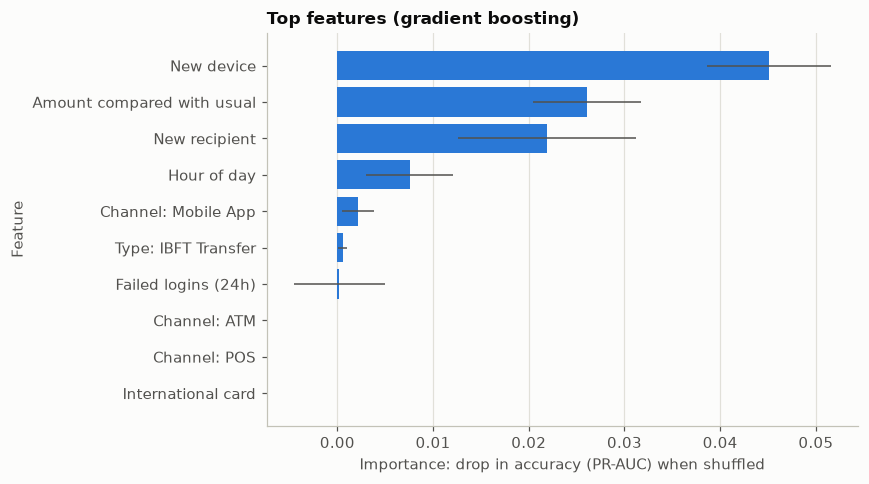

In [92]:
pi_gb = permutation_importance(gb, X_test, y_test, scoring="average_precision", n_repeats=20, random_state=0, n_jobs=1)
imp_gb = pd.DataFrame({"mean_drop": pi_gb.importances_mean, "std": pi_gb.importances_std}, index=X_test.columns).sort_values("mean_drop")
top = imp_gb.tail(10)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(nice_names(top.index), top["mean_drop"], xerr=top["std"], color=BLUE, ecolor=INK2, error_kw=dict(lw=1))
ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID)
ax.set_xlabel("Importance: drop in accuracy (PR-AUC) when shuffled"); ax.set_ylabel("Feature"); ax.set_title("Top features (gradient boosting)")
plt.tight_layout(); plt.show()

### Updated comparison: all techniques

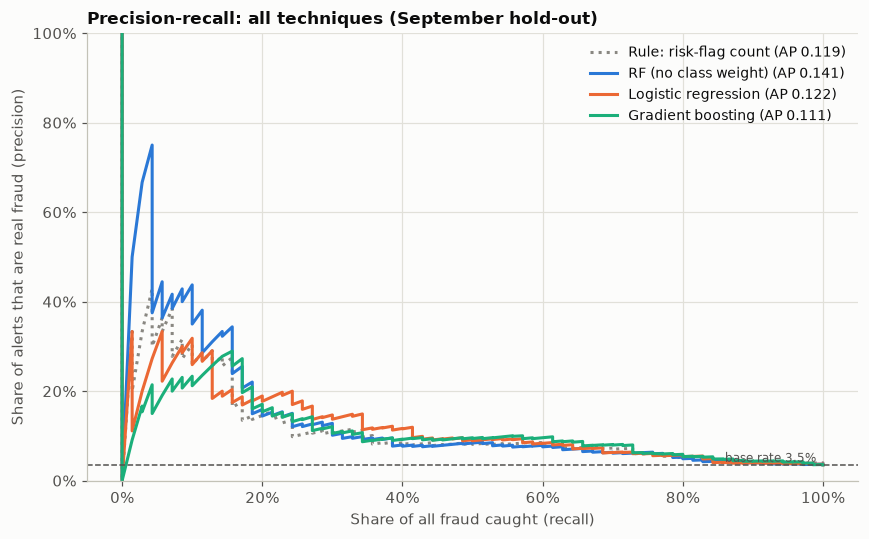

,PR-AUC,ROC-AUC,precision@top1%,precision@top5%,recall@top5%,recall@top10%
Rule: risk-flag count,0.119,0.715,0.30,0.152,0.214,0.314
RF (no class weight),0.141,0.703,0.35,0.152,0.214,0.300
Logistic regression,0.122,0.720,0.30,0.172,0.243,0.343
Gradient boosting,0.111,0.737,0.15,0.152,0.214,0.300


In [93]:
# Updated comparison: every technique on one precision-recall plot
curve_styles = {
    "Rule: risk-flag count": (rule_score_tb, MUTED, ":"),
    "RF (no class weight)": (scores["RF (no class weight)"], BLUE, "-"),
    "Logistic regression": (scores["Logistic regression"], ORANGE, "-"),
    "Gradient boosting": (scores["Gradient boosting"], "#1baf7a", "-"),
}
fig, ax = plt.subplots(figsize=(8, 5))
for name, (s, color, ls) in curve_styles.items():
    pr, rc, _ = precision_recall_curve(y_test, s)
    ax.plot(rc, pr, color=color, ls=ls, lw=2, label=f"{name} (AP {average_precision_score(y_test, s):.3f})")
ax.axhline(y_test.mean(), color=INK2, ls="--", lw=1)
ax.text(0.99, y_test.mean(), f" base rate {y_test.mean():.1%}", ha="right", va="bottom", fontsize=8, color=INK2)
ax.set_xlabel("Share of all fraud caught (recall)"); ax.set_ylabel("Share of alerts that are real fraud (precision)"); ax.set_ylim(0, 1.0)
ax.set_title("Precision-recall: all techniques (September hold-out)")
pct_axis(ax, "y"); pct_axis(ax, "x"); ax.grid(axis="x", color=GRID); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

comparison = pd.DataFrame({
    name: {"PR-AUC": average_precision_score(y_test, s), "ROC-AUC": roc_auc_score(y_test, s),
           "precision@top1%": alert_table(y_test, s, pcts=(0.01,))["precision"].iloc[0],
           "precision@top5%": alert_table(y_test, s, pcts=(0.05,))["precision"].iloc[0],
           "recall@top5%": alert_table(y_test, s, pcts=(0.05,))["recall"].iloc[0],
           "recall@top10%": alert_table(y_test, s, pcts=(0.10,))["recall"].iloc[0]}
    for name, (s, _, _) in curve_styles.items()
}).T
display(comparison.round(3))

### Gradient boosting findings
1. **It did not improve on the simpler models.** PR-AUC on September is 0.111 (95% CI 0.069-0.170), the lowest of the group (rule 0.119, logistic regression 0.122, random forest 0.141), though all intervals overlap heavily.
2. **Rankings disagree depending on the metric, which is itself a sign of noise.** Gradient boosting has the **highest ROC-AUC (0.737)** and the **highest recall when reviewing the top 20% (about 56%)**, but is the **weakest at the very top of the list**: only 3 frauds in the top 1% (20 alerts), vs 6-7 for the other methods. With 70 frauds in the test month, one or two cases swing these numbers.
3. **Simpler was better during tuning.** The best settings were the shallowest trees (depth 2) with large leaves and few iterations; deeper or longer-trained models scored worse on time-validation (worst configuration 0.086 vs best 0.124). That is the classic sign of a small number of frauds: extra model capacity just fits noise.
4. **Same drivers again:** `new_device`, then amount relative to the customer's norm, then `new_beneficiary`, then hour of day. Everything else contributes close to nothing.

**Where this leaves us:** four different approaches (a hand-made rule, random forest, logistic regression, gradient boosting) all land at PR-AUC of roughly 0.11-0.14 (about 3-4x better than random), and none is reliably better than another on 70 test frauds. The conclusion is not "pick the fanciest model" but that **the information in these features limits performance**, so the simplest explainable option, the risk-flag rule or regularised logistic regression, is the defensible recommendation.

## 7. Grouped cross-validation: a firmer model comparison (supplementary evidence)
The September hold-out has only 70 frauds, so the confidence intervals overlapped and no model could be separated from the simple rule. The EDA also showed **no time drift**, so the time split costs a lot of statistical power for little protection.

**Method:** stratified, **customer-grouped** 5-fold cross-validation over all 6,000 rows, repeated 3 times with different shuffles.
- **Grouped by customer:** no customer appears in both train and test, which removes customer-level leakage.
- **Stratified:** every fold keeps ~4% fraud.
- **All 245 frauds** are scored out-of-fold, vs 70 in the September hold-out.
- Review-volume metrics (precision at top N%) are computed **within each fold** and then pooled, because that is how a daily review queue would work.
- A **paired customer-level bootstrap** quantifies whether each model really beats the rule (same resampled customers for both).

*Note: the hyper-parameters (C, forest and boosting settings) were chosen earlier using July-August rows, which are also in these folds, so the models get a slight optimistic bias. The rule's thresholds were also picked from the EDA on all data, which favours the rule. The two biases partly offset.*

In [94]:
from sklearn.model_selection import StratifiedGroupKFold

# Grouped + stratified CV over ALL 6,000 rows: no customer appears in both train and test,
# every fold keeps ~4% fraud, and all 245 frauds are scored out-of-fold (vs 70 in the September hold-out).
groups = model_df["customer_id"].values
y_arr = y_all.values
Z_all = lr_features(X_all)

rule_all = (model_df["new_device_flag"] + model_df["new_beneficiary_flag"]
            + (model_df["failed_login_attempts_prev_24h"] >= 2).astype(int) + model_df["international_card_flag"]
            + (model_df["transaction_amount_pkr"] / model_df["avg_txn_amount_prev_30d_pkr"] >= 3).astype(int)
            + (model_df["txn_count_prev_24h"] >= 6).astype(int)).values.astype(float)
rule_all = rule_all + np.random.default_rng(1).uniform(0, 0.01, len(rule_all))

# Hyper-parameters fixed from the earlier tuning (note: chosen on Jul-Aug only, so no tuning on the CV folds)
def make_models():
    return {
        "Rule: risk-flag count": None,
        "Random forest": (RandomForestClassifier(**rf_params), X_all),
        "Logistic regression": (make_lr(best_C), Z_all),
        "Gradient boosting": (HistGradientBoostingClassifier(**gb_params), X_all),
    }

N_REPEATS, N_FOLDS = 3, 5
oof = {}      # oof[(repeat, model)] = out-of-fold scores
fold_id = {}  # fold_id[repeat] = fold index per row
for r in range(N_REPEATS):
    cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=r)
    folds_idx = np.zeros(len(y_arr), dtype=int)
    for name, spec in make_models().items():
        oof[(r, name)] = rule_all.copy() if spec is None else np.zeros(len(y_arr))
    for f, (tr, te) in enumerate(cv.split(X_all, y_arr, groups)):
        folds_idx[te] = f
        for name, spec in make_models().items():
            if spec is None:
                continue
            model, feats = spec
            model.fit(feats.iloc[tr], y_arr[tr])
            oof[(r, name)][te] = model.predict_proba(feats.iloc[te])[:, 1]
    fold_id[r] = folds_idx

# sanity checks: no customer leakage; fraud rate per fold
leak = sum(len(set(groups[(fold_id[0] == f)]) & set(groups[(fold_id[0] != f)])) for f in range(N_FOLDS))
print("Customers shared between a test fold and its training data:", leak)
print("Fraud rate per fold (repeat 0):", [f"{y_arr[fold_id[0] == f].mean():.1%}" for f in range(N_FOLDS)])

Customers shared between a test fold and its training data: 0
Fraud rate per fold (repeat 0): ['4.1%', '4.1%', '4.0%', '4.1%', '4.2%']


In [95]:
def topk_counts(y_true, s, p):
    k = max(1, int(round(len(y_true) * p))); o = np.argsort(-s, kind="stable")[:k]
    return y_true[o].sum(), k

model_names = list(make_models().keys())
rows = []
for name in model_names:
    per_repeat = []
    for r in range(N_REPEATS):
        s, fid = oof[(r, name)], fold_id[r]
        fold_ap = [average_precision_score(y_arr[fid == f], s[fid == f]) for f in range(N_FOLDS)]
        rec = {"fold_mean_PR-AUC": np.mean(fold_ap), "fold_std": np.std(fold_ap)}
        for p in (0.01, 0.02, 0.05, 0.10):   # review top p% *within each fold*, then pool the counts
            tp = alerts = 0
            for f in range(N_FOLDS):
                t, k = topk_counts(y_arr[fid == f], s[fid == f], p); tp += t; alerts += k
            rec[f"precision@top{int(p*100)}%"] = tp / alerts
            rec[f"recall@top{int(p*100)}%"] = tp / y_arr.sum()
        per_repeat.append(rec)
    rows.append(pd.DataFrame(per_repeat).mean().rename(name))
cv_results = pd.DataFrame(rows)
print(f"Grouped stratified {N_FOLDS}-fold CV, averaged over {N_REPEATS} repeats | base rate {y_arr.mean():.3f} | {y_arr.sum()} frauds scored")
display(cv_results.round(3))

Grouped stratified 5-fold CV, averaged over 3 repeats | base rate 0.041 | 245 frauds scored


,fold_mean_PR-AUC,fold_std,precision@top1%,recall@top1%,precision@top2%,recall@top2%,precision@top5%,recall@top5%,precision@top10%,recall@top10%
Rule: risk-flag count,0.134,0.020,0.289,0.071,0.194,0.095,0.154,0.189,0.123,0.301
Random forest,0.140,0.045,0.322,0.079,0.214,0.105,0.156,0.190,0.116,0.283
Logistic regression,0.157,0.039,0.306,0.075,0.264,0.129,0.181,0.222,0.137,0.335
Gradient boosting,0.142,0.043,0.272,0.067,0.253,0.124,0.158,0.193,0.111,0.271


In [96]:
# How sure are we about differences? Paired bootstrap, resampling whole CUSTOMERS (their rows stay together).
# Compares each model with the rule on the same resampled customers (repeat 0 out-of-fold scores).
rng = np.random.default_rng(7)
cust_codes, cust_index = pd.factorize(model_df["customer_id"])
rows_by_cust = [np.where(cust_codes == i)[0] for i in range(len(cust_index))]
fid0 = fold_id[0]

def cv_ap(idx, s):
    # PR-AUC computed fold-by-fold on the resampled rows, then averaged (same definition as the table above)
    out = []
    for f in range(N_FOLDS):
        sel = idx[fid0[idx] == f]
        if y_arr[sel].sum() > 0:
            out.append(average_precision_score(y_arr[sel], s[sel]))
    return np.mean(out)

diffs = {n: [] for n in model_names if n != "Rule: risk-flag count"}
for _ in range(300):
    pick = rng.integers(0, len(rows_by_cust), len(rows_by_cust))
    idx = np.concatenate([rows_by_cust[i] for i in pick])
    base_ap = cv_ap(idx, oof[(0, "Rule: risk-flag count")])
    for n in diffs:
        diffs[n].append(cv_ap(idx, oof[(0, n)]) - base_ap)

boot = pd.DataFrame({n: {"mean_diff_vs_rule": np.mean(d), "ci_low": np.percentile(d, 2.5), "ci_high": np.percentile(d, 97.5),
                         "P(model > rule)": np.mean(np.array(d) > 0)} for n, d in diffs.items()}).T
print("PR-AUC difference vs the rule (positive = model better), 95% bootstrap interval:")
display(boot.round(3))

PR-AUC difference vs the rule (positive = model better), 95% bootstrap interval:


,mean_diff_vs_rule,ci_low,ci_high,P(model > rule)
Random forest,0.011,-0.018,0.038,0.757
Logistic regression,0.025,0.002,0.051,0.983
Gradient boosting,0.015,-0.012,0.044,0.847


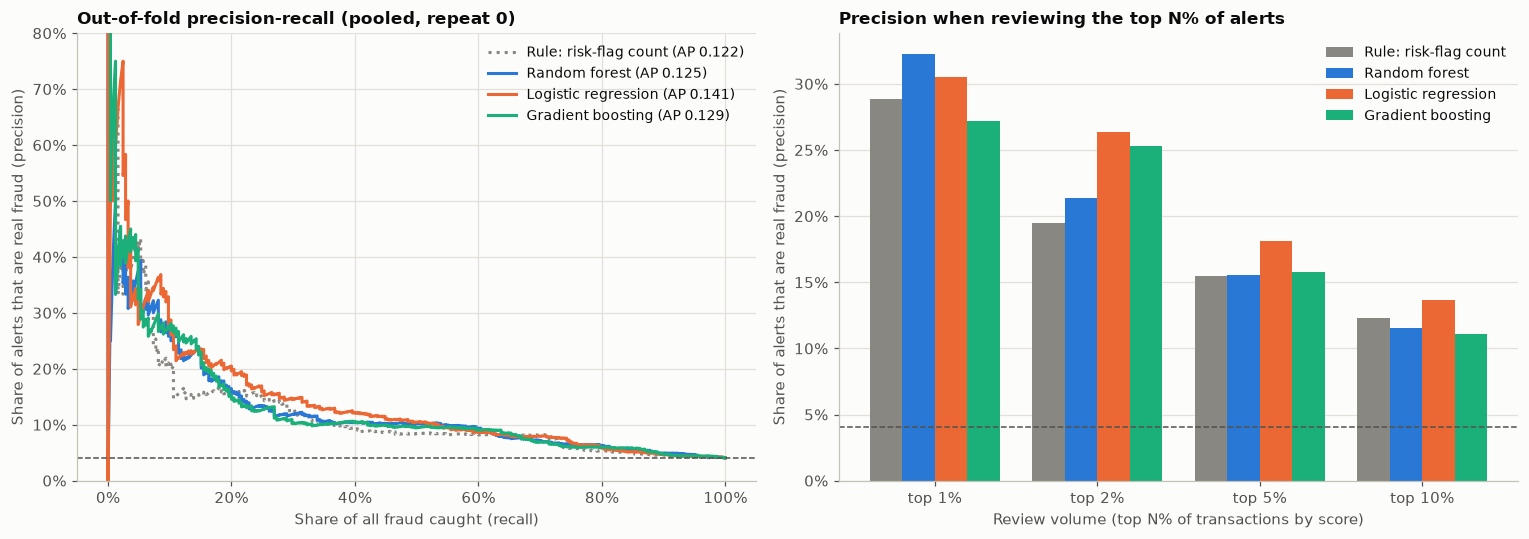

In [97]:
# Out-of-fold precision-recall curves (repeat 0): all 245 frauds, every row scored while its customer was unseen
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
styles = {"Rule: risk-flag count": (MUTED, ":"), "Random forest": (BLUE, "-"),
          "Logistic regression": (ORANGE, "-"), "Gradient boosting": ("#1baf7a", "-")}
for name, (color, ls) in styles.items():
    s = oof[(0, name)]
    pr, rc, _ = precision_recall_curve(y_arr, s)
    axes[0].plot(rc, pr, color=color, ls=ls, lw=2, label=f"{name} (AP {average_precision_score(y_arr, s):.3f})")
axes[0].axhline(y_arr.mean(), color=INK2, ls="--", lw=1)
axes[0].set_xlabel("Share of all fraud caught (recall)"); axes[0].set_ylabel("Share of alerts that are real fraud (precision)"); axes[0].set_ylim(0, 0.8)
axes[0].set_title("Out-of-fold precision-recall (pooled, repeat 0)")
pct_axis(axes[0], "y"); pct_axis(axes[0], "x"); axes[0].grid(axis="x", color=GRID); axes[0].legend(frameon=False, fontsize=9)

# Precision at fixed review volumes
pcts = [1, 2, 5, 10]
x = np.arange(len(pcts)); w = 0.2
for i, (name, (color, _)) in enumerate(styles.items()):
    vals = [cv_results.loc[name, f"precision@top{p}%"] for p in pcts]
    axes[1].bar(x + (i - 1.5) * w, vals, w, color=color, label=name)
axes[1].axhline(y_arr.mean(), color=INK2, ls="--", lw=1)
axes[1].set_xticks(x); axes[1].set_xticklabels([f"top {p}%" for p in pcts])
axes[1].set_xlabel("Review volume (top N% of transactions by score)"); axes[1].set_ylabel("Share of alerts that are real fraud (precision)")
axes[1].set_title("Precision when reviewing the top N% of alerts")
pct_axis(axes[1], "y"); axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

### Grouped CV findings
| Method | PR-AUC (fold mean) | Precision top 1% | Precision top 2% | Precision top 5% (recall) | Precision top 10% (recall) |
|---|---|---|---|---|---|
| Random (base rate) | ~0.041 | 4.1% | 4.1% | 4.1% | 4.1% |
| Rule: risk-flag count | 0.134 | 28.9% | 19.4% | 15.4% (18.9%) | 12.3% (30.1%) |
| Random forest | 0.140 | 32.2% | 21.4% | 15.6% (19.0%) | 11.6% (28.3%) |
| **Logistic regression** | **0.157** | 30.6% | **26.4%** | **18.1% (22.2%)** | **13.7% (33.5%)** |
| Gradient boosting | 0.142 | 27.2% | 25.3% | 15.8% (19.3%) | 11.1% (27.1%) |

1. **Logistic regression is the only model with evidence of beating the rule.** Its PR-AUC gain over the rule is **+0.025 (95% interval +0.002 to +0.051; 98% of bootstrap samples favour it)**. That is a modest effect (about 18% better in relative terms), but the interval stays above zero, unlike the other models.
2. **Random forest and gradient boosting are not distinguishable from the rule** (+0.011 and +0.015 with intervals that include zero). The extra complexity does not pay off.
3. **At the top of the list all methods are close** (precision about 27-32% at the top 1%), consistent with the September result. Differences appear in the broader review volumes: reviewing the top 5% with logistic regression gives **18.1% precision, catching 22% of fraud**; the top 10% catches about a third.
4. **Fold-to-fold noise is as large as the gaps** (standard deviation 0.02-0.045 in PR-AUC), so even with all 245 frauds the real differences between models are small. The overall message is unchanged: performance is limited by the information in the features, not the algorithm.
5. **No leakage:** zero customers are shared between a test fold and its training data, and fraud rates are balanced across folds (4.0-4.2%).

**recommendation:** use **regularised logistic regression** as the scoring model. It is at least as good as the alternatives on both validation schemes, is the only one with statistically supported improvement over the simple rule, and is **explainable** (each feature has a readable coefficient). 

## 8. What drives the score, and worked examples
The fraud team will not act on a bare score. They need to know **what the model relies on** and **what a typical alert looks like**.

**Feature importance for the recommended model (regularised logistic regression), two views:**
1. The **coefficient chart in section 5** shows the direction and size of each feature's effect across all transactions.
2. A **permutation test on September** (below): shuffle one feature at a time and measure how much PR-AUC drops. A bigger drop means the model relies on that feature more.

**Worked examples:** the highest-scoring alerts shown with the plain warning signs present, plus three cases: a correct catch, a false alarm and a missed fraud.

*Importance describes what the model uses, not what causes fraud. Features that overlap (for example hour of day and the night flag) share credit.*

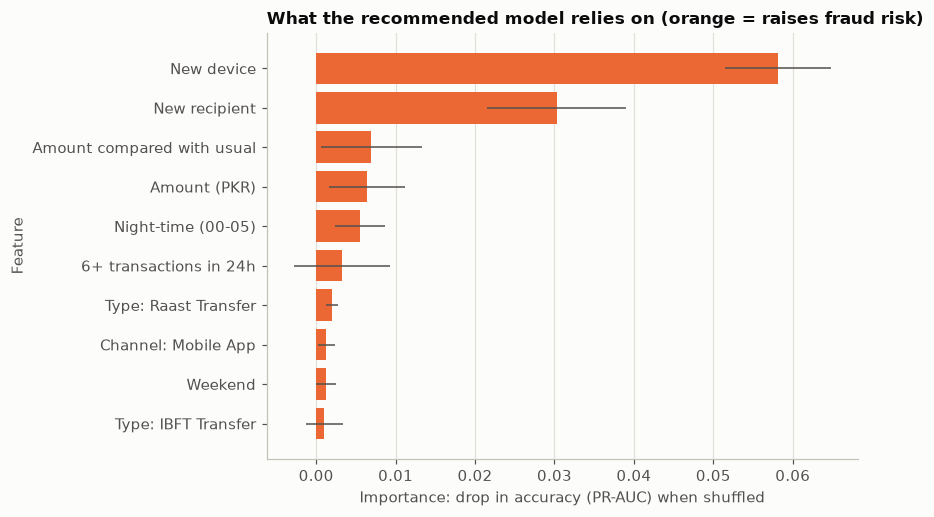

,importance (PR-AUC drop),std,effect
new_device,0.0581,0.0067,raises fraud risk
new_beneficiary,0.0303,0.0087,raises fraud risk
log_amt_ratio,0.0069,0.0064,raises fraud risk
log_amount,0.0064,0.0048,raises fraud risk
is_night,0.0055,0.0032,raises fraud risk
burst_6plus,0.0032,0.0061,raises fraud risk
type_Raast Transfer,0.0020,0.0007,raises fraud risk
chan_Mobile App,0.0013,0.0010,raises fraud risk
is_weekend,0.0012,0.0013,raises fraud risk
type_IBFT Transfer,0.0010,0.0023,raises fraud risk


In [98]:
# Feature importance for the recommended model (regularised logistic regression), measured on the held-out September data:
# shuffle one feature at a time and see how much PR-AUC drops. A bigger drop means the model relies on that feature more.
pi_lr = permutation_importance(lr_plain, Z_test, y_test, scoring="average_precision", n_repeats=30, random_state=0, n_jobs=1)
imp_lr = pd.DataFrame({"importance (PR-AUC drop)": pi_lr.importances_mean, "std": pi_lr.importances_std,
                       "effect": np.where(lr_plain[-1].coef_[0] > 0, "raises fraud risk", "lowers fraud risk")},
                      index=Z_test.columns).sort_values("importance (PR-AUC drop)", ascending=False)
top = imp_lr.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(nice_names(top.index), top["importance (PR-AUC drop)"], xerr=top["std"], ecolor=INK2, error_kw=dict(lw=1),
        color=[ORANGE if e == "raises fraud risk" else BLUE for e in top["effect"]])
ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID)
ax.set_xlabel("Importance: drop in accuracy (PR-AUC) when shuffled"); ax.set_ylabel("Feature")
ax.set_title("What the recommended model relies on (orange = raises fraud risk)")
plt.tight_layout(); plt.show()
display(imp_lr.head(10).round(4))

**Reading the importance:**
- **Two features carry most of the model:** **new device** (PR-AUC drops by 0.058 when shuffled) and **new beneficiary** (0.030). This matches the EDA and the coefficient chart in section 5.
- **Everything else is small** (0.007 or less): amount relative to the customer's usual, raw amount, night-time and the 6+ transactions burst. Their error bars are about as large as the bars themselves, so I would not rank them against each other.
- **Direction:** every one of the top ten features raises fraud risk, as the EDA suggested.
- **Type, channel and weekend add almost nothing** on top of the behaviour signals.

In [99]:
# What a fraud analyst would see: the highest-scoring September alerts, with the warning signs that are present.
test_rows = model_df.loc[~train_mask].reset_index(drop=True)
lr_scores = lr_plain.predict_proba(Z_test)[:, 1]

def warning_signs(r):
    ratio = r["transaction_amount_pkr"] / r["avg_txn_amount_prev_30d_pkr"]
    signs = []
    if r["new_device_flag"]: signs.append("new device")
    if r["new_beneficiary_flag"]: signs.append("new beneficiary")
    if ratio >= 3: signs.append(f"amount {ratio:.1f}x the customer's usual")
    if r["txn_count_prev_24h"] >= 6: signs.append(f"{r['txn_count_prev_24h']} transactions in the last 24h")
    if r["failed_login_attempts_prev_24h"] >= 2: signs.append(f"{r['failed_login_attempts_prev_24h']} failed logins in 24h")
    if r["transaction_datetime"].hour <= 5: signs.append("night-time (00-05)")
    if r["international_card_flag"]: signs.append("international card")
    return "; ".join(signs) if signs else "none of the warning signs"

order = np.argsort(-lr_scores)
rank_of = np.empty(len(order), dtype=int); rank_of[order] = np.arange(1, len(order) + 1)
top_alerts = pd.DataFrame({
    "rank": np.arange(1, 11),
    "transaction": test_rows.loc[order[:10], "transaction_id"].values,
    "amount_PKR": test_rows.loc[order[:10], "transaction_amount_pkr"].values,
    "warning signs present": [warning_signs(test_rows.iloc[i]) for i in order[:10]],
    "actually fraud": np.where(test_rows.loc[order[:10], "is_fraud"].values == 1, "yes", "no"),
})
pd.set_option("display.max_colwidth", 100)
display(top_alerts)
print("Of the 10 highest-scoring alerts,", int((top_alerts["actually fraud"] == "yes").sum()), "were confirmed fraud.")

# Three worked examples: a correct catch, a false alarm, and a missed fraud
top5 = order[:int(len(order) * 0.05)]
is_fraud_arr = test_rows["is_fraud"].values
caught = top5[is_fraud_arr[top5] == 1][0]                                  # highest-scoring true fraud inside the top 5%
false_alarm = order[is_fraud_arr[order] == 0][0]                           # highest-scoring legitimate transaction
missed = order[is_fraud_arr[order] == 1][-1]                               # lowest-scoring true fraud
rows = []
for label, i in [("Caught fraud", caught), ("False alarm", false_alarm), ("Missed fraud", missed)]:
    r = test_rows.iloc[i]
    rows.append({"example": label, "transaction": r["transaction_id"], "type / channel": f"{r['transaction_type']} / {r['channel']}",
                 "amount_PKR": r["transaction_amount_pkr"], "usual_PKR": r["avg_txn_amount_prev_30d_pkr"],
                 "score rank": f"{rank_of[i]:,} of {len(order):,}", "warning signs present": warning_signs(r)})
display(pd.DataFrame(rows).set_index("example"))

,rank,transaction,amount_PKR,warning signs present,actually fraud
0,1,TX805257,41499,new device; new beneficiary; 7 transactions in the last 24h; night-time (00-05),no
1,2,TX805664,1630,new device; new beneficiary; night-time (00-05),no
2,3,TX805829,14623,new device; new beneficiary; night-time (00-05),yes
3,4,TX805370,20944,new device; new beneficiary,no
4,5,TX804698,350000,new beneficiary; amount 12.4x the customer's usual; 9 transactions in the last 24h,no
5,6,TX804528,6590,new device; 9 transactions in the last 24h; night-time (00-05),no
6,7,TX804488,59511,new device; new beneficiary,no
7,8,TX804225,9518,new device; 3 failed logins in 24h; night-time (00-05),no
8,9,TX805832,5152,new device; 6 transactions in the last 24h; night-time (00-05),no
9,10,TX805291,17946,new device; new beneficiary; amount 3.9x the customer's usual,yes


Of the 10 highest-scoring alerts, 2 were confirmed fraud.


,transaction,type / channel,amount_PKR,usual_PKR,score rank,warning signs present
example,,,,,,
Caught fraud,TX805829,IBFT Transfer / Mobile App,14623,12279,"3 of 1,976",new device; new beneficiary; night-time (00-05)
False alarm,TX805257,Raast Transfer / Mobile App,41499,14236,"1 of 1,976",new device; new beneficiary; 7 transactions in the last 24h; night-time (00-05)
Missed fraud,TX805281,Bill Payment / Mobile App,4243,17021,"1,897 of 1,976",none of the warning signs


### What the alerts and examples show
1. **Every top alert shows several warning signs, and still most are legitimate.** All ten highest-scoring September alerts have at least two warning signs, yet only **2 of the 10** were confirmed fraud. A new device together with a new payee describes fraud, but also an ordinary customer who bought a new phone and paid someone new. This is why precision stays limited.
2. **Caught fraud:** an IBFT transfer of PKR 14,623 on the mobile app, with a new device, a new beneficiary and at night. It ranked **3rd of 1,976**.
3. **False alarm:** the single highest-scoring transaction (rank 1) was a Raast transfer of PKR 41,499 with a new device, a new beneficiary, 7 transactions in the last 24 hours and at night. It looks exactly like fraud, but the customer was genuine.
4. **Missed fraud:** a PKR 4,243 bill payment on the mobile app, ranked **1,897th of 1,976**, with **none of the warning signs**. This is the roughly 29% of fraud that looks like ordinary behaviour in these fields, and no model built on them could catch it.
5. **How the fraud team can use this:** show the score and the warning signs beside every alert so the analyst can check the facts quickly, and let the signs guide the action (for example a new device plus a new payee suggests a step-up check or a call to the customer).

## 9. Calibration: making the scores mean what they say (supplementary, needed for the probability settings)
The logistic regression ranks well but, because of strong regularisation, its scores are squeezed into a narrow range (top score about 11% even though the riskiest alerts are about 25-30% real fraud). A fraud team cannot treat such scores as probabilities. Calibration is a monotonic re-mapping, so it **does not change the ranking** (and therefore not PR-AUC), but it makes the numbers usable as real probabilities.

**Method:** Platt scaling (a small logistic regression on the model's log-odds), fitted on the **grouped-CV out-of-fold scores** and **cross-fitted** (fit on 4 folds, applied to the 5th) so the evaluation is not optimistic. Metrics: Brier score, log loss and a reliability diagram, compared with the raw scores.

In [100]:
from sklearn.metrics import brier_score_loss, log_loss

# Calibration: turn the logistic regression's compressed scores into real probabilities.
# Calibrate on the grouped-CV OUT-OF-FOLD scores (each score comes from a model that never saw that customer),
# and cross-fit the calibrator too (fit on 4 folds, apply to the 5th) so the evaluation is not optimistic.
raw = np.clip(oof[(0, "Logistic regression")], 1e-6, 1 - 1e-6)
fid0 = fold_id[0]
to_logit = lambda p: np.log(p / (1 - p))

platt_cal = np.zeros_like(raw)
for f in range(N_FOLDS):
    tr, te = fid0 != f, fid0 == f
    platt = LogisticRegression(C=1e6).fit(to_logit(raw[tr]).reshape(-1, 1), y_arr[tr])   # Platt: sigmoid on the logit
    platt_cal[te] = platt.predict_proba(to_logit(raw[te]).reshape(-1, 1))[:, 1]

versions = {"Raw scores": raw, "Platt (sigmoid)": platt_cal}
base_brier = brier_score_loss(y_arr, np.full(len(y_arr), y_arr.mean()))
cal_table = pd.DataFrame({
    name: {"Brier score": brier_score_loss(y_arr, s), "Brier skill vs base rate": 1 - brier_score_loss(y_arr, s) / base_brier,
           "Log loss": log_loss(y_arr, s), "PR-AUC (unchanged = ranking same)": average_precision_score(y_arr, s),
           "mean predicted": s.mean(), "max predicted": s.max()}
    for name, s in versions.items()}).T
print(f"Observed fraud rate: {y_arr.mean():.3f}")
display(cal_table.round(4))

Observed fraud rate: 0.041


,Brier score,Brier skill vs base rate,Log loss,PR-AUC (unchanged = ranking same),mean predicted,max predicted
Raw scores,0.0385,0.0157,0.1639,0.1412,0.0408,0.1109
Platt (sigmoid),0.0374,0.0444,0.1564,0.1385,0.0409,0.6102


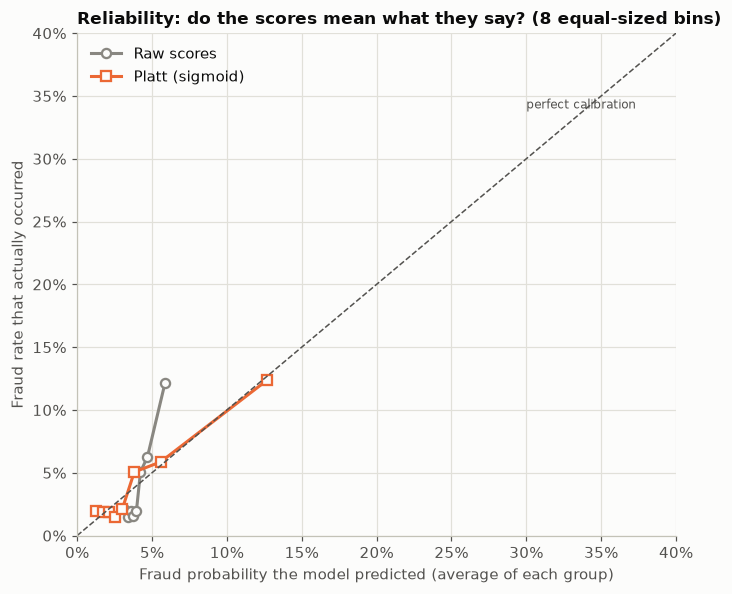

Raw scores:


,predicted,observed,n
bin,,,
"(0.0236, 0.0331]",0.031,0.021,750
"(0.0331, 0.035]",0.034,0.015,750
"(0.035, 0.0368]",0.036,0.020,750
"(0.0368, 0.0385]",0.038,0.016,750
"(0.0385, 0.0409]",0.040,0.020,750
"(0.0409, 0.0441]",0.042,0.051,750
"(0.0441, 0.0506]",0.047,0.063,750
"(0.0506, 0.111]",0.059,0.121,750


After Platt calibration:


,predicted,observed,n
bin,,,
"(0.00431, 0.0155]",0.013,0.020,750
"(0.0155, 0.0192]",0.017,0.019,750
"(0.0192, 0.023]",0.021,0.019,750
"(0.023, 0.0272]",0.025,0.015,750
"(0.0272, 0.0336]",0.030,0.021,750
"(0.0336, 0.0444]",0.038,0.051,750
"(0.0444, 0.0716]",0.056,0.059,750
"(0.0716, 0.61]",0.127,0.124,750


In [101]:
# Reliability diagram: if calibrated, predicted probability (x) matches the observed fraud rate (y)
def reliability(s, n_bins=8):
    q = pd.qcut(s, n_bins, duplicates="drop")
    g = pd.DataFrame({"p": s, "y": y_arr, "bin": q}).groupby("bin", observed=True).agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))
    return g

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for (name, s), color, mk in zip(versions.items(), [MUTED, ORANGE, BLUE], ["o", "s", "^"]):
    g = reliability(s)
    ax.plot(g["pred"], g["obs"], color=color, marker=mk, lw=2, ms=6, mfc=SURF, mew=1.5, label=name)
lim = 0.5
ax.plot([0, lim], [0, lim], color=INK2, ls="--", lw=1)
ax.text(0.30, 0.34, "perfect calibration", rotation=0, fontsize=8, color=INK2)
ax.set_xlim(0, 0.4); ax.set_ylim(0, 0.4)
ax.set_xlabel("Fraud probability the model predicted (average of each group)"); ax.set_ylabel("Fraud rate that actually occurred")
pct_axis(ax, "x"); pct_axis(ax, "y"); ax.grid(axis="x", color=GRID)
ax.set_title("Reliability: do the scores mean what they say? (8 equal-sized bins)")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print("Raw scores:"); display(reliability(raw).round(3).rename(columns={"pred": "predicted", "obs": "observed"}))
print("After Platt calibration:"); display(reliability(platt_cal).round(3).rename(columns={"pred": "predicted", "obs": "observed"}))

In [102]:
# Final deployable scorer = logistic regression trained on all data + Platt calibrator fitted on all out-of-fold scores.
final_lr = make_lr(best_C).fit(Z_all, y_arr)
final_platt = LogisticRegression(C=1e6).fit(to_logit(raw).reshape(-1, 1), y_arr)
print(f"Platt: calibrated_logit = {final_platt.coef_[0][0]:.2f} x raw_logit + {final_platt.intercept_[0]:.2f}")

def score_transactions(df_new):
    """Calibrated fraud probability for new transactions (same columns as the raw file)."""
    Z_new = lr_features(build_features(df_new))
    r_ = np.clip(final_lr.predict_proba(Z_new)[:, 1], 1e-6, 1 - 1e-6)
    return final_platt.predict_proba(to_logit(r_).reshape(-1, 1))[:, 1]

demo = score_transactions(model_df.head(2000))
print("Demo on 2,000 in-sample rows (illustration only): mean", f"{demo.mean():.3f}", "| max", f"{demo.max():.3f}")

Platt: calibrated_logit = 3.58 x raw_logit + 7.94
Demo on 2,000 in-sample rows (illustration only): mean 0.043 | max 0.629


C:\Users\mohib\AppData\Local\Temp\ipykernel_13448\3657751559.py:20: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  X["is_weekend"] = (d["transaction_datetime"].dt.dayofweek >= 5).astype(int)


### Calibration findings
1. **The raw scores were mis-scaled, not broken.** On average they matched the base rate (predicted 4.08% vs observed 4.1%), but they were **too compressed**: in the top bin the model said about 5.9% when the real fraud rate was 12.1%, and in the lowest bins it said about 3-4% when the real rate was about 2%.
2. **Platt scaling fixes it.** After calibration the top bin predicts 12.7% vs 12.4% observed, and the bins line up closely along the diagonal. Brier score improves (0.0385 to 0.0374) and log loss improves (0.164 to 0.156). The fitted slope of 3.6 on the log-odds shows how much the raw scores had to be stretched.
3. **Ranking is unchanged.** PR-AUC is the same up to small differences from fitting the calibrator separately in each fold.
4. **Usable output:** `score_transactions(df)` returns a calibrated fraud probability for any new transactions with the original columns. The Platt-calibrated probabilities are what the business analysis below uses.

*Caveat: this is calibrated on the sample's 4.1% fraud rate. If the real production fraud rate differs, the probabilities need re-calibrating (the ranking stays valid).*

## 10. The trade-off, and how the fraud team can act on it
Every review has a possible gain (a real fraud may be stopped) and a cost to the customer (a legitimate customer is contacted or delayed). Below is, for every 1,000 transactions, exactly what each review volume gives and what it costs, using the calibrated scores from section 9.

**No money figures are assumed.** The tables use counts and shares only, so the bank can judge the balance with its own numbers for analyst capacity and customer impact.

In [103]:
# ----- The trade-off: what happens at each review volume? -----
# Uses the calibrated out-of-fold fraud probabilities from section 9 (every score comes from a model that never saw that customer).
p_cal = platt_cal.copy()
amount = model_df["transaction_amount_pkr"].values.astype(float)
n_days = (model_df["transaction_datetime"].max() - model_df["transaction_datetime"].min()).days + 1
TXNS_PER_DAY = len(model_df) / n_days       # replace with the bank's real daily volume to rescale the "per day" figures
n_fraud, n_legit = int(y_arr.sum()), int((y_arr == 0).sum())
print(f"Sample: {len(model_df):,} transactions over {n_days} days (~{TXNS_PER_DAY:.0f}/day); {n_fraud} frauds ({n_fraud / len(model_df):.1%}), {n_legit:,} legitimate")

def fraud_operating_point(review_share=None, prob_threshold=None, txns_per_day=None):
    """What happens if the fraud team reviews a given volume? Give EXACTLY ONE of review_share / prob_threshold."""
    if (review_share is None) == (prob_threshold is None):
        raise ValueError("Give exactly one of review_share or prob_threshold")
    if review_share is not None:
        flagged = np.zeros(len(y_arr), dtype=bool)
        for f in range(N_FOLDS):
            idx = np.where(fold_id[0] == f)[0]
            k = max(1, int(round(len(idx) * review_share)))
            flagged[idx[np.argsort(-p_cal[idx], kind="stable")[:k]]] = True
    else:
        flagged = p_cal >= prob_threshold
    n = len(y_arr); alerts = int(flagged.sum()); tp = int((flagged & (y_arr == 1)).sum()); fp = alerts - tp
    return {"alerts (% of transactions)": alerts / n,
            "alerts per day": alerts / n * (txns_per_day or TXNS_PER_DAY),
            "alerts per 1,000 transactions": alerts / n * 1000,
            "real frauds caught (per 1,000)": tp / n * 1000,
            "legitimate transactions alerted (per 1,000)": fp / n * 1000,
            "frauds missed (per 1,000)": (n_fraud - tp) / n * 1000,
            "recall (share of frauds caught)": tp / n_fraud,
            "share of legitimate transactions alerted": fp / n_legit,
            "precision (alerts that are real fraud)": tp / max(alerts, 1),
            "false alarms per real fraud": fp / max(tp, 1),
            "share of fraud VALUE caught": amount[flagged & (y_arr == 1)].sum() / amount[y_arr == 1].sum(),
            "min probability alerted": float(p_cal[flagged].min()) if alerts else np.nan}

shares = [0.005, 0.01, 0.02, 0.03, 0.05, 0.10, 0.15]
sweep = pd.DataFrame([fraud_operating_point(review_share=s) for s in shares], index=[f"review top {s:.1%}" for s in shares])
show_cols = ["alerts per day", "alerts per 1,000 transactions", "real frauds caught (per 1,000)", "legitimate transactions alerted (per 1,000)",
             "frauds missed (per 1,000)", "recall (share of frauds caught)", "share of legitimate transactions alerted",
             "precision (alerts that are real fraud)"]
display(sweep[show_cols].round(3))

Sample: 6,000 transactions over 92 days (~65/day); 245 frauds (4.1%), 5,755 legitimate


,alerts per day,"alerts per 1,000 transactions","real frauds caught (per 1,000)","legitimate transactions alerted (per 1,000)","frauds missed (per 1,000)",recall (share of frauds caught),share of legitimate transactions alerted,precision (alerts that are real fraud)
review top 0.5%,0.326,5.0,1.833,3.167,39.000,0.045,0.003,0.367
review top 1.0%,0.652,10.0,3.167,6.833,37.667,0.078,0.007,0.317
review top 2.0%,1.304,20.0,5.167,14.833,35.667,0.127,0.015,0.258
review top 3.0%,1.957,30.0,6.833,23.167,34.000,0.167,0.024,0.228
review top 5.0%,3.261,50.0,9.167,40.833,31.667,0.224,0.043,0.183
review top 10.0%,6.522,100.0,13.833,86.167,27.000,0.339,0.090,0.138
review top 15.0%,9.783,150.0,17.500,132.500,23.333,0.429,0.138,0.117


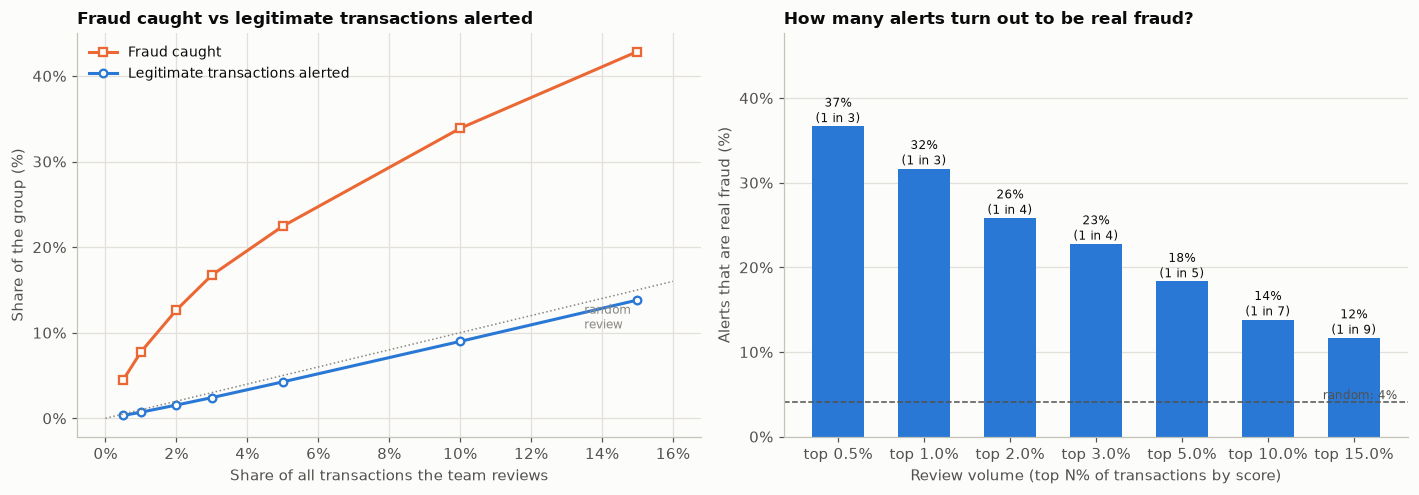

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
x = sweep["alerts (% of transactions)"]
axes[0].plot(x, sweep["recall (share of frauds caught)"], color=ORANGE, lw=2, marker="s", ms=5, mfc=SURF, mew=1.5, label="Fraud caught")
axes[0].plot(x, sweep["share of legitimate transactions alerted"], color=BLUE, lw=2, marker="o", ms=5, mfc=SURF, mew=1.5, label="Legitimate transactions alerted")
axes[0].plot([0, 0.16], [0, 0.16], color=MUTED, ls=":", lw=1)
axes[0].text(0.135, 0.105, "random\nreview", fontsize=8, color=MUTED)
axes[0].set_xlabel("Share of all transactions the team reviews"); axes[0].set_ylabel("Share of the group (%)")
axes[0].set_title("Fraud caught vs legitimate transactions alerted")
pct_axis(axes[0], "x"); pct_axis(axes[0], "y"); axes[0].grid(axis="x", color=GRID); axes[0].legend(frameon=False, fontsize=9)

axes[1].bar(np.arange(len(sweep)), sweep["precision (alerts that are real fraud)"], color=BLUE, width=0.6)
for i, v in enumerate(sweep["precision (alerts that are real fraud)"]):
    axes[1].text(i, v, f"{v:.0%}\n(1 in {1 / v:.0f})", ha="center", va="bottom", fontsize=8)
axes[1].axhline(y_arr.mean(), color=INK2, ls="--", lw=1)
axes[1].text(len(sweep) - 0.5, y_arr.mean(), f" random: {y_arr.mean():.0%}", va="bottom", ha="right", fontsize=8, color=INK2)
axes[1].set_xticks(np.arange(len(sweep))); axes[1].set_xticklabels([s.replace("review top ", "top ") for s in sweep.index])
axes[1].set_ylim(0, sweep["precision (alerts that are real fraud)"].max() * 1.3)
axes[1].set_xlabel("Review volume (top N% of transactions by score)"); axes[1].set_ylabel("Alerts that are real fraud (%)")
axes[1].set_title("How many alerts turn out to be real fraud?"); pct_axis(axes[1], "y")
plt.tight_layout(); plt.show()

**Reading the trade-off (per 1,000 transactions, about 41 of which are fraud):**
- **Review the top 1% (10 transactions, about 0.7 a day in this sample):** about **3 are real fraud and 7 are legitimate customers**. The team catches **8% of all fraud** and touches **0.7% of legitimate transactions**. Alerts are the most reliable here (about 1 in 3 is real).
- **Review the top 5% (50 transactions, about 3 a day):** about **9 real frauds and 41 legitimate transactions**. **22% of fraud is caught** while **4% of legitimate transactions** are alerted.
- **Review the top 10%:** 14 real frauds and 86 legitimate alerts; **34% of fraud caught**, 9% of legitimate transactions alerted.
- **Review the top 15%:** 17.5 real frauds and 132 legitimate alerts; **43% caught**, 14% of legitimate transactions alerted.
- **Each extra step costs more than the last.** Going from 5% to 15% finds about 8 more frauds but alerts about 92 more legitimate transactions, roughly **11 extra legitimate alerts for each extra fraud found**.
- **The ranking is clearly useful.** Reviewing the top 5% catches 22% of fraud; reviewing a random 5% would catch about 5%. The score is roughly 4 times better than random at that volume (and better still at the top 1%).
- **There is no setting that is both quiet and complete.** About 29% of frauds show none of the warning signs in these fields, so some fraud will always pass unnoticed.
- **The data cannot pick the "right" volume.** That depends on how many alerts analysts can handle and how the bank weighs a missed fraud against contacting a genuine customer. Section 11 lets the bank set that itself.

### Tiered action plan for the fraud operations team
Match the intensity of the action to how likely the transaction is fraud, so most customers are never touched:

In [105]:
# Tiered action plan: define tiers by score percentile within each fold, pool the outcomes
tier_edges = [("Tier 1: block + call customer", 0.00, 0.01), ("Tier 2: step-up verification", 0.01, 0.05),
              ("Tier 3: silent monitoring / watchlist", 0.05, 0.15), ("Tier 4: pass", 0.15, 1.00)]
total_fraud_value = amount[y_arr == 1].sum()
rows = []
for name, lo, hi in tier_edges:
    n = fr = val = 0
    for f in range(N_FOLDS):
        m = fold_id[0] == f
        o = np.argsort(-p_cal[m], kind="stable"); a, b = int(round(m.sum() * lo)), int(round(m.sum() * hi))
        sel = o[a:b]; yy, aa = y_arr[m][sel], amount[m][sel]
        n += len(sel); fr += yy.sum(); val += aa[yy == 1].sum()
    rows.append({"tier": name, "share of txns": hi - lo, "alerts per 10,000 txns": round((hi - lo) * 10000),
                 "fraud rate (precision)": fr / n, "false alarms per fraud": (n - fr) / max(fr, 1),
                 "% of all fraud": fr / y_arr.sum(), "% of fraud value": val / total_fraud_value})
tiers = pd.DataFrame(rows).set_index("tier")
display(tiers.round(3))
print(f"Reference: overall fraud rate {y_arr.mean():.1%}. At ~{len(model_df) / n_days:.0f} txns/day in this sample, Tier 1 is ~{len(model_df) / n_days * 0.01:.1f} alerts/day and Tier 2 ~{len(model_df) / n_days * 0.04:.1f}/day.")

,share of txns,"alerts per 10,000 txns",fraud rate (precision),false alarms per fraud,% of all fraud,% of fraud value
tier,,,,,,
Tier 1: block + call customer,0.01,100,0.317,2.158,0.078,0.094
Tier 2: step-up verification,0.04,400,0.150,5.667,0.147,0.195
Tier 3: silent monitoring / watchlist,0.10,1000,0.083,11.000,0.204,0.262
Tier 4: pass,0.85,8500,0.027,35.429,0.571,0.449


Reference: overall fraud rate 4.1%. At ~65 txns/day in this sample, Tier 1 is ~0.7 alerts/day and Tier 2 ~2.6/day.


### How the fraud operations team can use this
| Tier | Score percentile | Action | Why |
|---|---|---|---|
| **1: block + call customer** | Top 1% | Hold the transaction, call the customer to confirm | About 32% of these are real fraud (about 8x the base rate); worth the heavier action. About 0.7 alerts a day at this sample's volume. |
| **2: step-up verification** | Next 4% | In-app challenge (OTP/biometric) before releasing | About 15% real fraud (about 3.7x base). A light challenge only takes a legitimate customer a few seconds, so a wrong alert here is a minor inconvenience. |
| **3: silent monitoring** | Next 10% | No interruption; tighten monitoring, queue for next-day review, escalate if more signals appear | About 8% real fraud: not enough to justify interrupting customers, but worth watching. |
| **4: pass** | Bottom 85% | Normal processing | Fraud rate 2.7%, below the average. |

**How each alert reaches the analyst:** score and tier, the **warning signs present** (new device, new beneficiary, amount well above the customer's usual, and so on), and the amount, with the queue worked **largest amount first** within a tier.

**What the numbers say honestly:**
- **Tiers 1-3 cover 15% of transactions but hold 43% of all fraud and 55% of fraud value.** That is a real concentration (a random 15% would hold 15%).
- **57% of fraud still sits in the "pass" tier**, because these features cannot see it. The model is a **prioritisation aid, not a safety net**. Other controls (limits, velocity rules, customer reporting channels) must stay in place.
- **Monitoring loop:** track precision per tier and the reasons behind false alarms, **re-calibrate** when the fraud rate drifts, and **pilot** with a controlled trial (e.g. step-up verification for a random half of Tier 2) to measure the real effect and the impact on customers before relying on these estimates.

## 11. Control panel: how the bank tunes the alert volume
**The question this answers:** *"We get too many alerts that are not fraud (or too few, and fraud is slipping through). Can we change that ourselves?"* **Yes, without retraining anything.** The model produces a score; the only decision left is **where to draw the line**. That line is one dial, and the bank can set it two ways:

| Way to set the dial | Parameter | Use it when |
|---|---|---|
| **By capacity** | `review_share` (e.g. 2% of transactions) | "Our analysts can review about N alerts a day" |
| **By risk** | `prob_threshold` (e.g. alert at 15% fraud probability) | "We only want to act when fraud is at least this likely" (valid because the scores were calibrated in section 9) |

| Symptom | What to turn |
|---|---|
| **Too many alerts that are not fraud** | Lower `review_share` / raise `prob_threshold` |
| **Fraud slipping through, analysts have spare time** | Raise `review_share` / lower `prob_threshold` |
| **Fraud rate in production differs from this sample** | Re-calibrate the probabilities (the capacity setting stays valid; probability cut-offs move) |

*Results are out-of-fold estimates on this sample. The table in section 10 shows what each setting means; the helpers below find a setting from a goal.*

### Setting the dial from a goal
Instead of guessing a percentage, state the limit and let the helper find the largest volume that respects it:

In [106]:
# ---- Set the dial from a business goal instead of guessing ----
def fraud_find_setting(min_precision=None, max_alerts_per_day=None, max_false_alarms_per_fraud=None):
    """Largest review volume that still respects every limit given (more volume = more fraud caught)."""
    best = None
    for sh in np.arange(0.005, 0.30, 0.0025):
        r = fraud_operating_point(review_share=sh)
        ok = ((min_precision is None or r["precision (alerts that are real fraud)"] >= min_precision)
              and (max_alerts_per_day is None or r["alerts per day"] <= max_alerts_per_day)
              and (max_false_alarms_per_fraud is None or r["false alarms per real fraud"] <= max_false_alarms_per_fraud))
        if ok:
            best = (sh, r)
    return best

goals = {"Fewer unnecessary investigations: at least 1 in 4 alerts must be real fraud": dict(min_precision=0.25),
         "Analysts can handle at most 2 alerts a day": dict(max_alerts_per_day=2),
         "No more than 4 false alarms per real fraud": dict(max_false_alarms_per_fraud=4),
         "At most 4 alerts a day AND at least 15% precision": dict(max_alerts_per_day=4, min_precision=0.15)}
rows = {}
for name, kw in goals.items():
    res = fraud_find_setting(**kw)
    if res is None:
        rows[name] = {"review share": "no setting meets the goal"}
    else:
        sh, r = res
        rows[name] = {"review share": f"{sh:.2%}", **{k: v for k, v in r.items() if k in
                      ["alerts per day", "precision (alerts that are real fraud)", "recall (share of frauds caught)", "share of fraud VALUE caught"]}}
display(pd.DataFrame(rows).T)
print(f"(Daily figures assume {TXNS_PER_DAY:.0f} transactions per day, the sample's volume. Change TXNS_PER_DAY to the bank's real volume.)")

,review share,alerts per day,recall (share of frauds caught),precision (alerts that are real fraud),share of fraud VALUE caught
Fewer unnecessary investigations: at least 1 in 4 alerts must be real fraud,2.00%,1.304348,0.126531,0.258333,0.222758
Analysts can handle at most 2 alerts a day,3.00%,1.956522,0.167347,0.227778,0.242675
No more than 4 false alarms per real fraud,4.00%,2.608696,0.195918,0.2,0.26759
At most 4 alerts a day AND at least 15% precision,6.00%,3.913043,0.240816,0.163889,0.329413


(Daily figures assume 65 transactions per day, the sample's volume. Change TXNS_PER_DAY to the bank's real volume.)


**Reading:** each business limit translates into a concrete setting, and shows what it costs in missed fraud.
- *"At least 1 in 4 alerts must be real"* -> alert **2%** of transactions (1.3 a day), catching 13% of frauds.
- *"Analysts handle 2 alerts a day"* -> **3%**, 23% precision, 17% of frauds caught.
- *"No more than 4 false alarms per fraud"* -> **4%**, 20% precision, 20% caught.
- *"Up to 4 alerts a day but at least 15% precision"* -> **6%**, 16% precision, 24% caught.

Change `TXNS_PER_DAY` to the bank's real volume and the alerts-per-day figures rescale automatically.

### The action tiers are settings too
The tier shares (1% / 5% / 15%) are parameters. Change `FRAUD_TIERS` and the probability cut-offs, and the actions, follow. `assign_fraud_action` maps any new transaction's calibrated probability (from `score_transactions`) to its action.

In [107]:
# ---- The action tiers are also settings: change the shares and the probability cut-offs follow ----
FRAUD_TIERS = {"Tier 1: block + call customer": 0.01,       # cumulative share of transactions
               "Tier 2: step-up verification": 0.05,
               "Tier 3: silent monitoring": 0.15}

def fraud_tier_cutoffs(tiers=FRAUD_TIERS):
    return {name: float(np.quantile(p_cal, 1 - share)) for name, share in tiers.items()}

def assign_fraud_action(prob, cutoffs):
    """Map calibrated fraud probabilities to an action (works on new transactions scored by score_transactions)."""
    names = list(cutoffs); prob = np.asarray(prob)
    out = np.full(len(prob), "Tier 4: pass", dtype=object)
    for name in reversed(names):                 # least severe first, so the most severe tier overwrites
        out[prob >= cutoffs[name]] = name
    return out

cuts = fraud_tier_cutoffs()
print("Probability cut-offs for the current tier shares:", {k: f"{v:.1%}" for k, v in cuts.items()})
act = pd.DataFrame({"action": assign_fraud_action(p_cal, cuts), "fraud": y_arr})
summary = act.groupby("action")["fraud"].agg(transactions="size", fraud_rate="mean", frauds="sum")
summary["share of transactions"] = summary["transactions"] / len(act)
display(summary.round(3))

Probability cut-offs for the current tier shares: {'Tier 1: block + call customer': '22.8%', 'Tier 2: step-up verification': '11.4%', 'Tier 3: silent monitoring': '6.3%'}


,transactions,fraud_rate,frauds,share of transactions
action,,,,
Tier 1: block + call customer,60,0.317,19,0.01
Tier 2: step-up verification,240,0.142,34,0.04
Tier 3: silent monitoring,600,0.087,52,0.10
Tier 4: pass,5100,0.027,140,0.85


**Reading:** with the current shares the cut-offs are about **23%** (Tier 1), **11%** (Tier 2) and **6%** (Tier 3). Tier 1 is 32% real fraud, Tier 2 14%, Tier 3 9%, and the pass group 2.7%. Moving a cut-off moves a transaction between actions without touching the model.

### How the bank should use this in practice
1. **Start conservative** (for example `review_share = 2%`) and watch the share of alerts that turn out to be fraud.
2. **Review weekly:** if analysts are overloaded with unnecessary investigations, lower the dial; if they have spare capacity and fraud losses are rising, raise it.
3. **Agree the balance with the business:** how much customer inconvenience is acceptable, and how much undetected fraud. This notebook deliberately assumes no money values; the bank's own figures should guide the setting.
4. **Re-check calibration monthly.** If the production fraud rate drifts from about 4%, refit the calibrator; capacity-based settings (`review_share`) stay valid, probability-based ones need new cut-offs.
5. **Pilot first.** Apply the new setting to a controlled subset and measure the real share of unnecessary alerts before relying on these estimates.